# SI3003 · Evaluación 2 · Parte II (aplicada) — Notebook base

**Profesor:** Jorge Iván Padilla Buriticá · Universidad EAFIT

Este notebook es **una ayuda, no una solución**. Trae la infraestructura (configuración, carga de datos, utilidades) y deja **esqueletos vacíos** para lo que se califica. Puede borrar, mover o cambiar lo que quiera.

| Etiqueta en la celda | Significado |
|---|---|
| `# [PROVISTO]` | Ya funciona. Léala y entiéndala; puede modificarla. |
| `# [SU TURNO]` | Aquí va **su** código o **su** análisis. |

> ⏱ **Tiempo máximo: 60 minutos.** Si una tarea se complica, avance y deje escrito qué intentó.
> 📨 **Entrega:** un único notebook **ejecutado de arriba hacia abajo**, enviado a **jipadillab@eafit.edu.co** con el asunto `[SI3003-Nombre_Apellido_Grupo_Eval02_practica]`, **hasta las 11:00 a. m.** (la celda final le imprime su asunto).

## ✅ Antes del examen: qué debe tener preparado

- [ ] **Al menos un proveedor de chat con clave** guardada en **Colab Secrets** (🔑 en la barra izquierda, con *acceso al notebook* activado): `NVIDIA_API_KEY`, `GROQ_API_KEY` o `HF_TOKEN`. **Pruébela con un *ping*** y anote el **nombre exacto del modelo** que funcionó (los catálogos cambian).
- [ ] **Modelos locales ya descargados** (ejecute la celda *Precalentamiento* en casa): `gpt2`, el modelo de embeddings oficial (ver `embedding_info.json`), `all-MiniLM-L6-v2` y el tokenizador de `tiktoken`.
- [ ] **Acceso a la carpeta de Drive** del examen y la carpeta `datos_examen/` copiada a Colab (ver celda de datos).
- [ ] El **enunciado PDF** de la Parte II abierto en otra pestaña.
- [ ] **No necesita GPU**: todo corre en CPU.
- [ ] Repase las **reglas de compatibilidad R1–R4** del enunciado (abajo, resumidas).

### Reglas de compatibilidad (resumen)
1. **Mismo modelo de embeddings** (y mismos parámetros: `input_type`/prefijos, `dimensions`, normalización) para indexar y consultar.
2. **Misma dimensión ≠ compatible.** Dos modelos de 384 dimensiones producen espacios distintos.
3. El **LLM de generación es independiente** del embedding: puede cambiar de proveedor de chat sin reindexar.
4. Los **parámetros específicos de un proveedor** (`extra_body` de NVIDIA, `logprobs` en Groq) pueden dar error 400 en otro: aíslelos.

| Proveedor | Chat | Embeddings |
|---|---|---|
| NVIDIA NIM | Sí | Sí (con `input_type` en modelos asimétricos) |
| Groq | Sí | **No** |
| Hugging Face (router) | Sí | No por ese endpoint (use `feature_extraction` o un modelo local) |
| Local | Sí (lento) | Sí |

## 0 · Configuración inicial

In [1]:
# [PROVISTO] Instalación. En Colab tarda ~1-2 min. Si ya lo instaló, omítala.
# %pip install -q openai "sentence-transformers<4" rank_bm25 faiss-cpu tiktoken "transformers<5" pandas matplotlib python-dotenv
print("✅ Entorno y dependencias verificadas.")

✅ Entorno y dependencias verificadas.


In [2]:
# [PROVISTO] PRECALENTAMIENTO — ejecútela ANTES del examen (en casa) para dejar los modelos en caché.
# Cambie el primer modelo si embedding_info.json indica otro.
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM
import tiktoken
_ = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
_ = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
_ = AutoTokenizer.from_pretrained("gpt2"); _ = AutoModelForCausalLM.from_pretrained("gpt2")
_ = tiktoken.get_encoding("cl100k_base")
print("✅ Modelos locales listos")

✅ Modelos locales listos


In [3]:
# [SU TURNO] Sus datos. Todo lo demás se calcula a partir de aquí.
STUDENT_NAME = "Santiago Vasquez"     # Nombre y apellido
STUDENT_ID   = "1000357979"           # Documento de identidad (solo dígitos)
GROUP        = "01"                   # Grupo de SI3003

In [4]:
# [PROVISTO] Semilla, dígito personal, cronómetro y asunto del correo.
import time, random, numpy as np
assert STUDENT_ID.isdigit() and len(STUDENT_ID) >= 4, "Escriba su documento (solo dígitos)"
SEED = int(STUDENT_ID[-4:])     # últimos 4 dígitos
D    = int(STUDENT_ID[-1])      # último dígito (define su subconjunto en A.3)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch; torch.manual_seed(SEED)
except ImportError:
    pass
T0 = time.time()
def tiempo(): print(f"⏱ {(time.time()-T0)/60:.1f} min transcurridos de 60")
ASUNTO = f"[SI3003-{STUDENT_NAME.strip().replace(' ', '_')}_{GROUP}_Eval02_practica]"
print("SEED =", SEED, "| D =", D); print("Asunto del correo:", ASUNTO)

SEED = 7979 | D = 9
Asunto del correo: [SI3003-Santiago_Vasquez_01_Eval02_practica]


In [5]:
# [PROVISTO] Lectura segura de claves: Colab Secrets -> archivo .env / variable de entorno -> (opcional) getpass.
# NUNCA imprima una clave ni la escriba en una celda.
import os, getpass
from dotenv import load_dotenv
load_dotenv()

def get_secret(name, ask=False):
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception:
        pass
    v = os.getenv(name)
    if not v and ask:
        v = getpass.getpass(f"{name}: ").strip()
    return v or None

CLAVES_DISPONIBLES = {k: bool(get_secret(k)) for k in ["NVIDIA_API_KEY", "GROQ_API_KEY", "HF_TOKEN"]}
print("Claves disponibles (sin mostrarlas):", CLAVES_DISPONIBLES)

Claves disponibles (sin mostrarlas): {'NVIDIA_API_KEY': True, 'GROQ_API_KEY': False, 'HF_TOKEN': False}


In [6]:
# [PROVISTO] Carpeta de datos. Elija UNA opción.
from pathlib import Path
# Opción A (Colab + Drive): descomente y ajuste la ruta
# from google.colab import drive; drive.mount('/content/drive')
# DATA_DIR = Path('/content/drive/MyDrive/<ruta-a-la-carpeta>/datos_examen')
# Opción B: suba la carpeta a /content/datos_examen
DATA_DIR = Path("datos_examen")

ESPERADOS = ["yolo_results_scratch.csv", "yolo_results_pretrained.csv", "yolo_results_freeze.csv",
             "yolo_test_preds.json", "yolo_test_gt.json", "embedding_info.json",
             "corpus_reglamento.json", "preguntas_eval.json", "corpus_embeddings.npy",
             "question_embeddings.npy", "faithfulness_cases.json"]
def revisar_archivos():
    ok = True
    for f in ESPERADOS:
        existe = (DATA_DIR / f).exists(); ok &= existe
        print("✅" if existe else "❌", f)
    return ok
revisar_archivos()

✅ yolo_results_scratch.csv
✅ yolo_results_pretrained.csv
✅ yolo_results_freeze.csv
✅ yolo_test_preds.json
✅ yolo_test_gt.json
✅ embedding_info.json
✅ corpus_reglamento.json
✅ preguntas_eval.json
✅ corpus_embeddings.npy
✅ question_embeddings.npy
✅ faithfulness_cases.json


True

## SECCIÓN A — CNN y detección con YOLO (33 pts)

### A.1 · Dimensiones y parámetros (5 pts)
Qué debe entregar: `conv_out` implementada · 3 configuraciones validadas con `assert` contra `torch.nn.Conv2d` (**una con stride 2 y una con padding**) · la red de la **Pregunta 1 de la Parte I** construida en PyTorch, con la forma de cada capa y el total de parámetros, comparados con su cálculo a mano.

In [7]:
# [SU TURNO] A.1 — Función conv_out y validación con assert contra torch.nn.Conv2d
import torch
import torch.nn as nn
import pandas as pd

def conv_out(W: int, K: int, P: int, S: int) -> int:
    """Calcula el tamaño espacial de salida O = floor((W - K + 2P) / S) + 1."""
    return (W - K + 2 * P) // S + 1

# Tres configuraciones de prueba (incluyendo padding y stride 2)
configuraciones = [
    {"Caso": "1. Estándar con padding (same)", "C_in": 3, "C_out": 8,  "W": 32, "K": 3, "P": 1, "S": 1},
    {"Caso": "2. Con reducción por stride 2",  "C_in": 8, "C_out": 16, "W": 16, "K": 3, "P": 1, "S": 2},
    {"Caso": "3. Sin padding y kernel 5x5",    "C_in": 1, "C_out": 4,  "W": 30, "K": 5, "P": 0, "S": 2},
]

filas_conv = []
for cfg in configuraciones:
    W, K, P, S = cfg["W"], cfg["K"], cfg["P"], cfg["S"]
    o_manual = conv_out(W, K, P, S)
    capa_conv = nn.Conv2d(cfg["C_in"], cfg["C_out"], kernel_size=K, stride=S, padding=P)
    with torch.no_grad():
        y = capa_conv(torch.zeros(1, cfg["C_in"], W, W))
    o_torch = y.shape[-1]
    assert o_manual == o_torch, f"Discrepancia en {cfg['Caso']}: {o_manual} != {o_torch}"
    filas_conv.append({
        "Configuración": cfg["Caso"],
        "(W, K, P, S)": f"({W}, {K}, {P}, {S})",
        "conv_out (Fórmula)": o_manual,
        "nn.Conv2d.shape[-1]": o_torch,
        "Forma tensor salida": tuple(y.shape),
        "Validación": "✅ OK"
    })

print("✅ Los 3 asserts de conv_out contra torch.nn.Conv2d pasaron exitosamente.")
pd.DataFrame(filas_conv)

✅ Los 3 asserts de conv_out contra torch.nn.Conv2d pasaron exitosamente.


,Configuración,"(W, K, P, S)",conv_out (Fórmula),nn.Conv2d.shape[-1],Forma tensor salida,Validación
0,1. Estándar con padding (same),"(32, 3, 1, 1)",32,32,"(1, 8, 32, 32)",✅ OK
1,2. Con reducción por stride 2,"(16, 3, 1, 2)",8,8,"(1, 16, 8, 8)",✅ OK
2,3. Sin padding y kernel 5x5,"(30, 5, 0, 2)",13,13,"(1, 4, 13, 13)",✅ OK


In [8]:
# [SU TURNO] A.1 — Red de la Pregunta 1 (Parte I): forma tras cada capa y conteo de parámetros
class RedPregunta1(nn.Module):
    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.conv1   = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3, stride=1, padding=1)
        self.relu1   = nn.ReLU()
        self.pool1   = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2   = nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, stride=2, padding=1)
        self.relu2   = nn.ReLU()
        self.gap     = nn.AdaptiveAvgPool2d((1, 1))
        self.flatten = nn.Flatten()
        self.fc      = nn.Linear(in_features=16, out_features=num_classes)
        self.softmax = nn.Softmax(dim=-1)

    def forward_trace(self, x):
        pasos = [
            ("Entrada (RGB 32x32)", x, 0, "—"),
        ]
        x = self.relu1(self.conv1(x))
        pasos.append(("Conv1 (8@3x3, s=1, p=1) + ReLU", x, sum(p.numel() for p in self.conv1.parameters()), "(3*3*3 + 1)*8 = 224"))
        x = self.pool1(x)
        pasos.append(("Pool1 (MaxPool 2x2, s=2)", x, 0, "0 (sin pesos)"))
        x = self.relu2(self.conv2(x))
        pasos.append(("Conv2 (16@3x3, s=2, p=1) + ReLU", x, sum(p.numel() for p in self.conv2.parameters()), "(3*3*8 + 1)*16 = 1168"))
        x = self.gap(x)
        pasos.append(("GAP (AdaptiveAvgPool2d 1x1)", x, 0, "0 (sin pesos)"))
        x = self.flatten(x)
        pasos.append(("Flatten", x, 0, "0 (sin pesos)"))
        x = self.softmax(self.fc(x))
        pasos.append(("FC (16 -> 10) + Softmax", x, sum(p.numel() for p in self.fc.parameters()), "(16 + 1)*10 = 170"))
        return x, pasos

torch.manual_seed(SEED)
modelo_p1 = RedPregunta1(num_classes=10)
x_dummy = torch.zeros(1, 3, 32, 32)
with torch.no_grad():
    salida_p1, traza = modelo_p1.forward_trace(x_dummy)

df_capas = pd.DataFrame([
    {
        "Capa": nombre,
        "Forma PyTorch (B, C, H, W)": tuple(tensor.shape),
        "Alto x Ancho x Canales (Teoría)": (
            f"{tensor.shape[2]}x{tensor.shape[3]}x{tensor.shape[1]}"
            if tensor.ndim == 4 else f"{tensor.shape[1]}"
        ),
        "Parámetros PyTorch": n_params,
        "Cálculo Manual (Parte I)": formula_manual,
    }
    for nombre, tensor, n_params, formula_manual in traza
])

total_params_pytorch = sum(p.numel() for p in modelo_p1.parameters())
total_params_manual  = 224 + 1168 + 170
assert total_params_pytorch == total_params_manual == 1562, f"Error en total de parámetros: {total_params_pytorch}"

print(f"✅ Total de parámetros entrenables (PyTorch): {total_params_pytorch} == Cálculo a mano (Parte I): {total_params_manual}")
print("   Contraste Pregunta 1(c): Con Flatten directo tras Conv2 (8x8x16=1024), la FC tendría (1024+1)*10 = 10,250 parámetros (60.29x más que los 170 con GAP).")
print("   Contraste Pregunta 1(d): Una FC de 1000 neuronas sobre 32x32x3 tendría (3072+1)*1000 = 3,073,000 parámetros vs. 224 en Conv1 (conectividad local + pesos compartidos).")
df_capas

✅ Total de parámetros entrenables (PyTorch): 1562 == Cálculo a mano (Parte I): 1562
   Contraste Pregunta 1(c): Con Flatten directo tras Conv2 (8x8x16=1024), la FC tendría (1024+1)*10 = 10,250 parámetros (60.29x más que los 170 con GAP).
   Contraste Pregunta 1(d): Una FC de 1000 neuronas sobre 32x32x3 tendría (3072+1)*1000 = 3,073,000 parámetros vs. 224 en Conv1 (conectividad local + pesos compartidos).


,Capa,"Forma PyTorch (B, C, H, W)",Alto x Ancho x Canales (Teoría),Parámetros PyTorch,Cálculo Manual (Parte I)
0,Entrada (RGB 32x32),"(1, 3, 32, 32)",32x32x3,0,—
1,"Conv1 (8@3x3, s=1, p=1) + ReLU","(1, 8, 32, 32)",32x32x8,224,(3*3*3 + 1)*8 = 224
2,"Pool1 (MaxPool 2x2, s=2)","(1, 8, 16, 16)",16x16x8,0,0 (sin pesos)
3,"Conv2 (16@3x3, s=2, p=1) + ReLU","(1, 16, 8, 8)",8x8x16,1168,(3*3*8 + 1)*16 = 1168
4,GAP (AdaptiveAvgPool2d 1x1),"(1, 16, 1, 1)",1x1x16,0,0 (sin pesos)
5,Flatten,"(1, 16)",16,0,0 (sin pesos)
6,FC (16 -> 10) + Softmax,"(1, 10)",10,170,(16 + 1)*10 = 170


### A.2 · Comparación de las tres estrategias (12 pts)
Qué debe entregar: **(4)** gráfica con pérdida de caja de entrenamiento y mAP50 por época de los 3 modelos · **(3)** tabla con valores **finales** de mAP50, mAP50-95, precision, recall y tiempo total · **(5)** análisis (máx. 150 palabras) con evidencia de *sus* gráficas.

In [9]:
# [PROVISTO] Carga de los tres CSV. Revise los nombres de columna antes de graficar.
import pandas as pd, matplotlib.pyplot as plt
runs = {}
for nombre in ["scratch", "pretrained", "freeze"]:
    df = pd.read_csv(DATA_DIR / f"yolo_results_{nombre}.csv")
    df.columns = df.columns.str.strip()          # Ultralytics deja espacios en los nombres
    runs[nombre] = df
print(list(runs["pretrained"].columns))
runs["pretrained"].head(3)

['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,8.99,1.58423,1.92457,1.32650,0.45205,0.38580,0.33581,0.17100,1.58151,1.97556,1.42030,0.0009,0.0009,0.0009
1,2,17.89,1.35361,1.48921,1.20194,0.57181,0.49487,0.48483,0.25377,1.36286,1.75433,1.27045,0.0008,0.0008,0.0008
2,3,26.99,1.22114,1.26948,1.15532,0.63927,0.56712,0.57237,0.30450,1.26630,1.61992,1.19248,0.0007,0.0007,0.0007


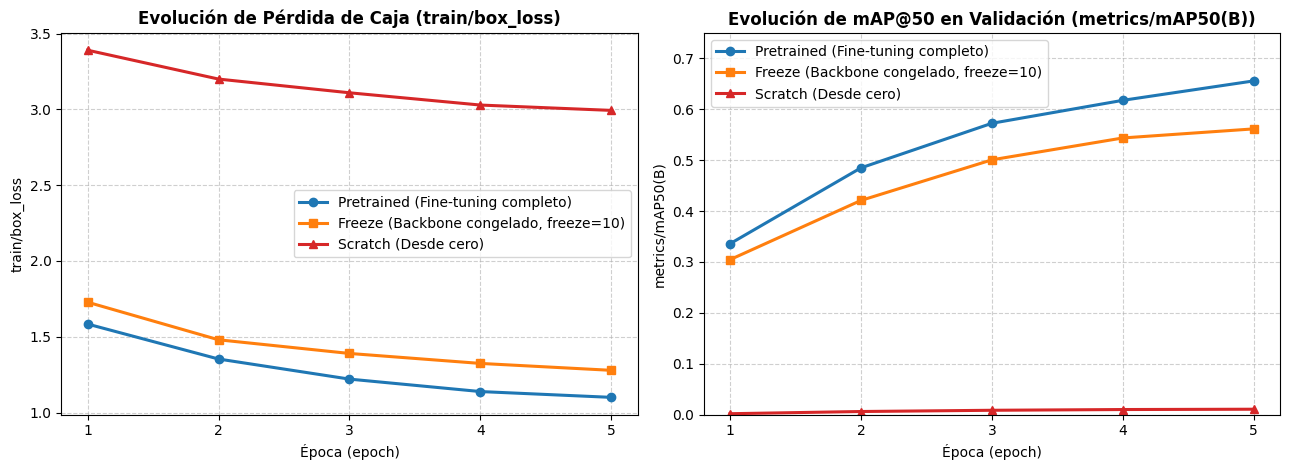

Tabla de valores finales en la época 5 (nota: en Ultralytics la columna 'time' registra el tiempo acumulado en segundos hasta esa época):


,Estrategia,Época Final,train/box_loss (inicial -> final),mAP50 final,mAP50-95 final,Precision final,Recall final,"Tiempo total (últ. época, s)",Suma col. time (s)
0,pretrained,5,1.5842 -> 1.1008,0.6556,0.3572,0.7066,0.6313,45.25,135.57
1,freeze,5,1.7283 -> 1.2791,0.5614,0.3017,0.6660,0.5582,32.05,95.28
2,scratch,5,3.3901 -> 2.9931,0.0108,0.0046,0.0738,0.0457,44.85,133.10


In [10]:
# [SU TURNO] A.2 — Gráficas (pérdida de caja y mAP50 por época) y tabla de valores finales
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
estilos = {
    "pretrained": {"label": "Pretrained (Fine-tuning completo)", "color": "#1f77b4", "marker": "o", "lw": 2.2},
    "freeze":     {"label": "Freeze (Backbone congelado, freeze=10)", "color": "#ff7f0e", "marker": "s", "lw": 2.2},
    "scratch":    {"label": "Scratch (Desde cero)", "color": "#d62728", "marker": "^", "lw": 2.2},
}

for nombre in ["pretrained", "freeze", "scratch"]:
    df = runs[nombre]
    est = estilos[nombre]
    axes[0].plot(df["epoch"], df["train/box_loss"], label=est["label"], color=est["color"], marker=est["marker"], linewidth=est["lw"])
    axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], label=est["label"], color=est["color"], marker=est["marker"], linewidth=est["lw"])

axes[0].set_title("Evolución de Pérdida de Caja (train/box_loss)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Época (epoch)")
axes[0].set_ylabel("train/box_loss")
axes[0].set_xticks(runs["pretrained"]["epoch"])
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend()

axes[1].set_title("Evolución de mAP@50 en Validación (metrics/mAP50(B))", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Época (epoch)")
axes[1].set_ylabel("metrics/mAP50(B)")
axes[1].set_xticks(runs["pretrained"]["epoch"])
axes[1].set_ylim(0, 0.75)
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

# Tabla comparativa de valores finales (última época = época 5)
filas_yolo = []
for nombre in ["pretrained", "freeze", "scratch"]:
    df = runs[nombre]
    ult = df.iloc[-1]
    filas_yolo.append({
        "Estrategia": nombre,
        "Época Final": int(ult["epoch"]),
        "train/box_loss (inicial -> final)": f"{df['train/box_loss'].iloc[0]:.4f} -> {ult['train/box_loss']:.4f}",
        "mAP50 final": round(float(ult["metrics/mAP50(B)"]), 4),
        "mAP50-95 final": round(float(ult["metrics/mAP50-95(B)"]), 4),
        "Precision final": round(float(ult["metrics/precision(B)"]), 4),
        "Recall final": round(float(ult["metrics/recall(B)"]), 4),
        "Tiempo total (últ. época, s)": round(float(ult["time"]), 2),
        "Suma col. time (s)": round(float(df["time"].sum()), 2),
    })

df_yolo_final = pd.DataFrame(filas_yolo)
print("Tabla de valores finales en la época 5 (nota: en Ultralytics la columna 'time' registra el tiempo acumulado en segundos hasta esa época):")
df_yolo_final

**[SU TURNO] A.2 — Análisis (máx. 150 palabras).**

El orden de desempeño es **`pretrained` > `freeze` $\gg$ `scratch`**. En las gráficas, `pretrained` converge más rápido y alcanza en la época 5 el mayor `mAP50` (**0.6556**), `mAP50-95` (**0.3572**), `precision` (**0.7066**), `recall` (**0.6313**) y la menor pérdida `train/box_loss` ($1.5842 \to 1.1008$). `freeze` logra el segundo lugar (`mAP50` = **0.5614**, `mAP50-95` = **0.3017**, `box_loss` = **1.2791**) pero entrena un **29.2% más rápido** (**32.05 s** vs. **45.25 s** acumulados) al congelar 10 capas del *backbone*. En cambio, `scratch` apenas reduce `box_loss` ($3.3901 \to 2.9931$) y colapsa en `mAP50` (**0.0108**), pues 5 épocas son insuficientes para aprender filtros visuales desde cero.

Con un dataset **10 veces mayor** y un **dominio muy distinto** al de preentrenamiento (Clase 8), usaría **fine-tuning completo (`pretrained` descongelado) o entrenamiento desde `scratch`**, descartando `freeze`: las características de bajo/medio nivel de COCO no transfieren al nuevo dominio y el mayor volumen de datos permite optimizar todas las capas sin sobreajuste.

### A.3 · IoU, NMS y evaluación manual (16 pts)
Qué debe entregar: **(5)** `iou` y `nms` con `assert` (incluya un caso de NMS con 4 cajas que elimine un duplicado) · **(3)** NMS **por clase** sobre sus 10 imágenes, con conteo de cajas antes/después · **(6)** TP, FP, FN, precision y recall con `conf=0.25` y `conf=0.5`, en una tabla · **(2)** explicación del *trade-off* con *sus* números.

In [11]:
# [PROVISTO] Carga de predicciones/ground truth y SU subconjunto de 10 imágenes (image_id % 3 == D % 3).
import json
preds = json.load(open(DATA_DIR / "yolo_test_preds.json"))   # {image_id: [{box, cls, conf}, ...]}
gts   = json.load(open(DATA_DIR / "yolo_test_gt.json"))      # {image_id: [{box, cls}, ...]}
mis_ids = [i for i in sorted(preds, key=int) if int(i) % 3 == D % 3]
assert len(mis_ids) == 10, len(mis_ids)
print("Sus imágenes:", mis_ids)

Sus imágenes: ['0', '3', '6', '9', '12', '15', '18', '21', '24', '27']


In [12]:
# [SU TURNO] A.3 — Implementación de iou y nms con pruebas automáticas (assert)
def iou(a, b) -> float:
    """Calcula Intersection over Union (IoU) para dos cajas en formato (x1, y1, x2, y2)."""
    inter_x1 = max(a[0], b[0])
    inter_y1 = max(a[1], b[1])
    inter_x2 = min(a[2], b[2])
    inter_y2 = min(a[3], b[3])
    inter_w  = max(0.0, inter_x2 - inter_x1)
    inter_h  = max(0.0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h

    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    union_area = area_a + area_b - inter_area
    return inter_area / union_area if union_area > 0.0 else 0.0

def nms(boxes, scores, iou_thr: float = 0.5, score_thr: float = 0.0):
    """Greedy Non-Maximum Suppression: devuelve los índices originales conservados ordenados por score descendente."""
    candidatos = [i for i, s in enumerate(scores) if s >= score_thr]
    candidatos.sort(key=lambda i: scores[i], reverse=True)
    conservados = []
    while candidatos:
        actual = candidatos.pop(0)
        conservados.append(actual)
        candidatos = [
            i for i in candidatos
            if iou(boxes[actual], boxes[i]) <= iou_thr
        ]
    return conservados

# 1. Assert de IoU del enunciado (Pregunta 2b de la Parte I: área intersección = 4, unión = 16 + 16 - 4 = 28 -> IoU = 4/28 = 1/7 ≈ 0.1429)
iou_prueba = iou((2, 2, 6, 6), (4, 4, 8, 8))
assert abs(iou_prueba - (4 / 28)) < 1e-6, f"IoU incorrecto: {iou_prueba}"
print(f"✅ Assert IoU((2,2,6,6), (4,4,8,8)) = {iou_prueba:.4f} (exacto 4/28 = {4/28:.4f})")

# 2. Caso sintético de NMS con 4 cajas que elimina duplicados y filtra por score_thr
cajas_sinteticas = [
    [10, 10, 50, 50],  # idx 0: caja principal (score 0.95)
    [12, 12, 52, 52],  # idx 1: duplicado muy solapado con idx 0 (IoU = 1444/1756 = 0.822 > 0.5) -> se suprime
    [100, 100, 140, 140], # idx 2: segundo objeto distinto (score 0.80, IoU = 0 con idx 0) -> se conserva
    [102, 102, 142, 142], # idx 3: duplicado muy solapado con idx 2 (score 0.60, IoU = 0.822 > 0.5) -> se suprime
]
scores_sinteticos = [0.95, 0.88, 0.80, 0.60]
indices_nms = nms(cajas_sinteticas, scores_sinteticos, iou_thr=0.5, score_thr=0.25)
assert indices_nms == [0, 2], f"Se esperaba conservar [0, 2], pero se obtuvo {indices_nms}"
print(f"✅ Assert NMS sintético con 4 cajas: de 4 cajas iniciales se conservaron los índices {indices_nms} (suprimidos duplicados 1 y 3).")

✅ Assert IoU((2,2,6,6), (4,4,8,8)) = 0.1429 (exacto 4/28 = 0.1429)
✅ Assert NMS sintético con 4 cajas: de 4 cajas iniciales se conservaron los índices [0, 2] (suprimidos duplicados 1 y 3).


In [13]:
# [SU TURNO] A.3 — NMS por clase sobre las 10 imágenes y evaluación manual TP/FP/FN/Precision/Recall
def nms_por_clase(pred_list, iou_thr: float = 0.5, score_thr: float = 0.0):
    """Aplica NMS de forma independiente por cada clase c y devuelve las predicciones sobrevivientes."""
    clases = sorted(set(p["cls"] for p in pred_list))
    sobrevivientes = []
    for c in clases:
        sub = [p for p in pred_list if p["cls"] == c]
        boxes  = [p["box"] for p in sub]
        scores = [p["conf"] for p in sub]
        keep_idx = nms(boxes, scores, iou_thr=iou_thr, score_thr=score_thr)
        sobrevivientes.extend(sub[i] for i in keep_idx)
    sobrevivientes.sort(key=lambda x: x["conf"], reverse=True)
    return sobrevivientes

# Conteo antes y después de NMS por clase en las 10 imágenes asignadas (D = 9 -> image_id % 3 == 0)
desglose_imgs = []
preds_post_nms = {}
for img_id in mis_ids:
     crudas = preds[img_id]
     limpias = nms_por_clase(crudas, iou_thr=0.5, score_thr=0.0)
     preds_post_nms[img_id] = limpias
     desglose_imgs.append({
         "image_id": img_id,
         "GT (cajas reales)": len(gts[img_id]),
         "Antes de NMS": len(crudas),
         "Después de NMS (score>=0.0)": len(limpias),
         "Después de NMS (conf>=0.25)": len(nms_por_clase(crudas, iou_thr=0.5, score_thr=0.25)),
         "Después de NMS (conf>=0.50)": len(nms_por_clase(crudas, iou_thr=0.5, score_thr=0.50)),
     })

df_desglose = pd.DataFrame(desglose_imgs)
tot_antes   = int(df_desglose["Antes de NMS"].sum())
tot_despues = int(df_desglose["Después de NMS (score>=0.0)"].sum())
tot_gt      = int(df_desglose["GT (cajas reales)"].sum())
print(f"📊 Resumen en las 10 imágenes (IDs {mis_ids}):")
print(f"   • Total cajas Ground Truth : {tot_gt}")
print(f"   • Cajas predichas ANTES de NMS : {tot_antes}")
print(f"   • Cajas predichas DESPUÉS de NMS por clase (iou_thr=0.5): {tot_despues} ({tot_antes - tot_despues} duplicados eliminados)")
print(f"   • Cajas sobrevivientes con conf >= 0.25: {int(df_desglose['Después de NMS (conf>=0.25)'].sum())} | con conf >= 0.50: {int(df_desglose['Después de NMS (conf>=0.50)'].sum())}\n")

# Emparejamiento codicioso (greedy matching) con Ground Truth para conf = 0.25 y conf = 0.50
def evaluar_detecciones(umbral_conf: float, iou_match_thr: float = 0.5):
    TP = FP = FN = 0
    for img_id in mis_ids:
        gt_img = gts[img_id]
        # Aplicamos NMS por clase con el umbral de confianza (idéntico a filtrar preds_post_nms por conf >= umbral_conf)
        pred_img = nms_por_clase(preds[img_id], iou_thr=0.5, score_thr=umbral_conf)
        assert len(pred_img) == len([p for p in preds_post_nms[img_id] if p["conf"] >= umbral_conf])

        gt_usados = set()
        for p in pred_img:  # ya están ordenadas por confianza de mayor a menor
            mejor_iou = 0.0
            mejor_j   = -1
            for j, g in enumerate(gt_img):
                if j in gt_usados or g["cls"] != p["cls"]:
                    continue
                val_iou = iou(p["box"], g["box"])
                if val_iou > iou_match_thr and val_iou > mejor_iou:
                    mejor_iou = val_iou
                    mejor_j   = j
            if mejor_j != -1:
                TP += 1
                gt_usados.add(mejor_j)
            else:
                FP += 1
        FN += len(gt_img) - len(gt_usados)

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall    = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {
        "Umbral de confianza (conf)": umbral_conf,
        "Predicciones post-NMS (TP+FP)": TP + FP,
        "Cajas reales GT (TP+FN)": TP + FN,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-Score": round(f1, 4),
    }

df_eval_nms = pd.DataFrame([evaluar_detecciones(0.25), evaluar_detecciones(0.50)])
df_eval_nms

📊 Resumen en las 10 imágenes (IDs ['0', '3', '6', '9', '12', '15', '18', '21', '24', '27']):
   • Total cajas Ground Truth : 143
   • Cajas predichas ANTES de NMS : 196
   • Cajas predichas DESPUÉS de NMS por clase (iou_thr=0.5): 145 (51 duplicados eliminados)
   • Cajas sobrevivientes con conf >= 0.25: 139 | con conf >= 0.50: 97



,Umbral de confianza (conf),Predicciones post-NMS (TP+FP),Cajas reales GT (TP+FN),TP,FP,FN,Precision,Recall,F1-Score
0,0.25,139,143,111,28,32,0.7986,0.7762,0.7872
1,0.50,97,143,84,13,59,0.8660,0.5874,0.7000


**[SU TURNO] A.3 — Explicación (2 pts).**

Al elevar el umbral de confianza de `conf = 0.25` a `conf = 0.50`, el detector se vuelve más conservador y descarta las **42 predicciones** post-NMS cuya confianza está en el intervalo $[0.25, 0.50)$ (pasando de **139** a **97** detecciones totales sobre las 10 imágenes):

1. **Por qué sube la Precision (`0.7986` $\to$ `0.8660`, $+6.74\text{ pp}$):** Entre esas 42 detecciones descartadas de confianza media-baja había **15 falsos positivos**, por lo que `FP` cae a menos de la mitad (de **28** a **13**, una reducción del $53.6\%$). Como las 97 predicciones que sobreviven tienen mayor certeza estadística, la fracción de aciertos sobre el total predicho $\text{Precision} = \frac{\text{TP}}{\text{TP}+\text{FP}}$ sube de $111/139 = 0.7986$ a $84/97 = 0.8660$.
2. **Por qué baja el Recall (`0.7762` $\to$ `0.5874`, $-18.88\text{ pp}$):** Las otras **27 predicciones** descartadas en $[0.25, 0.50)$ eran detecciones verdaderas de objetos reales difíciles o parcialmente ocluidos. Al eliminarlas, `TP` disminuye de **111** a **84** y esas 27 cajas reales pasan a engrosar los falsos negativos (`FN` sube de **32** a **59** sobre los **143** objetos reales), reduciendo la cobertura $\text{Recall} = \frac{\text{TP}}{\text{TP}+\text{FN}}$ de $111/143 = 0.7762$ a $84/143 = 0.5874$.

## SECCIÓN B — Transformers y NLP (30 pts)

### B.1 · Atención causal desde cero (12 pts)
Qué debe entregar: **(6)** `causal_self_attention(X, Wq, Wk, Wv)` de **una cabeza**, sin `nn.MultiheadAttention` ni funciones de atención ya hechas · **(3)** tres `assert`: filas suman 1, triángulo superior = 0, coincide (tol. 1e-5) con `F.scaled_dot_product_attention(..., is_causal=True)` · **(3)** reproduzca el ejemplo de la **Pregunta 4 de la Parte I** y compárelo con su resultado a mano.

In [14]:
# [PROVISTO] Datos de prueba generados con SU semilla (5 tokens, dimensión 8; W de 8x4).
import torch, math, torch.nn.functional as F
g  = torch.Generator().manual_seed(SEED)
X  = torch.randn(5, 8, generator=g)
Wq = torch.randn(8, 4, generator=g); Wk = torch.randn(8, 4, generator=g); Wv = torch.randn(8, 4, generator=g)

In [15]:
# [SU TURNO] B.1 — Atención causal de una cabeza desde cero, asserts y reproducción de la Pregunta 4 (Parte I)
def causal_self_attention(X: torch.Tensor, Wq: torch.Tensor, Wk: torch.Tensor, Wv: torch.Tensor):
    """
    Auto-atención causal de una cabeza desde cero en PyTorch.
    X:  (T, d)
    Wq: (d, d_k), Wk: (d, d_k), Wv: (d, d_v)
    Devuelve: (salida (T, d_v), matriz_de_atención A (T, T))
    """
    Q = X @ Wq
    K = X @ Wk
    V = X @ Wv
    T, d_k = Q.shape

    # Scores escalados: S = (Q @ K^T) / sqrt(d_k)
    scores = (Q @ K.transpose(-2, -1)) / math.sqrt(d_k)

    # Máscara causal triangular superior estricta (j > i recibe -inf)
    mask = torch.triu(torch.full((T, T), float("-inf"), dtype=scores.dtype, device=scores.device), diagonal=1)
    scores_masked = scores + mask

    # Pesos de atención por fila
    A = torch.softmax(scores_masked, dim=-1)

    # Suma ponderada de valores
    salida = A @ V
    return salida, A

# Ejecución con los tensores de prueba (5x8 y 8x4) generados con SEED = 7979
salida_b1, A_b1 = causal_self_attention(X, Wq, Wk, Wv)

# --- TRES ASSERTS OBLIGATORIOS (B.1.2) ---
# (i) Las filas de la matriz de atención suman 1
assert torch.allclose(A_b1.sum(dim=-1), torch.ones(X.shape[0]), atol=1e-5), "Las filas de A no suman 1"
# (ii) El triángulo superior estricto es exactamente 0
assert torch.all(torch.triu(A_b1, diagonal=1) == 0), "El triángulo superior no es 0"
# (iii) Coincide con F.scaled_dot_product_attention(..., is_causal=True) con tolerancia 1e-5
ref_b1 = F.scaled_dot_product_attention(X @ Wq, X @ Wk, X @ Wv, is_causal=True)
max_diff = torch.max(torch.abs(salida_b1 - ref_b1)).item()
assert torch.allclose(salida_b1, ref_b1, atol=1e-5), f"Difiere de PyTorch SDPA: max_diff={max_diff}"

print(f"✅ Assert (i) pasado: suma por filas de A = {A_b1.sum(dim=-1).tolist()}")
print(f"✅ Assert (ii) pasado: norma del triángulo superior estricto = {torch.triu(A_b1, diagonal=1).abs().sum().item():.1f}")
print(f"✅ Assert (iii) pasado: diferencia máxima contra F.scaled_dot_product_attention = {max_diff:.2e} (< 1e-5)\n")

# --- REPRODUCCIÓN DEL EJEMPLO DE LA PREGUNTA 4 DE LA PARTE I (B.1.3) ---
# En la Pregunta 4: 3 tokens, d_k = 4, q_3 = [1, 1, 1, 1],
# k_1 = [2, 2, 0, 0], v_1 = [1, 0]; k_2 = [1, 1, 0, 0], v_2 = [0, 1]; k_3 = [1, -1, 0, 0], v_3 = [1, 1].
# Pasamos directamente Q, K, V usando X = I_3 (identidad 3x3) y Wq = Q, Wk = K, Wv = V:
I3 = torch.eye(3, dtype=torch.float32)
Q_p4 = torch.tensor([
    [1.0, 0.0, 0.0, 0.0],  # q1 (cualquier vector para token 1; por máscara causal solo se atiende a sí mismo)
    [0.0, 1.0, 0.0, 0.0],  # q2
    [1.0, 1.0, 1.0, 1.0],  # q3 dado en el enunciado
])
K_p4 = torch.tensor([
    [2.0,  2.0, 0.0, 0.0], # k1
    [1.0,  1.0, 0.0, 0.0], # k2
    [1.0, -1.0, 0.0, 0.0], # k3
])
V_p4 = torch.tensor([
    [1.0, 0.0],            # v1
    [0.0, 1.0],            # v2
    [1.0, 1.0],            # v3
])

out_p4, A_p4 = causal_self_attention(I3, Q_p4, K_p4, V_p4)
scores_q3 = (Q_p4[2] @ K_p4.T) / math.sqrt(4)

# Cálculo a mano de la Parte I (usando e^0=1, e^1=2.718, e^2=7.389 del encabezado del examen impreso):
Z_mano  = 7.389 + 2.718 + 1.0  # 11.107
a3_mano = [7.389 / Z_mano, 2.718 / Z_mano, 1.0 / Z_mano]
out3_mano = [a3_mano[0]*1 + a3_mano[1]*0 + a3_mano[2]*1, a3_mano[0]*0 + a3_mano[1]*1 + a3_mano[2]*1]

print("=== Comparación Pregunta 4 (Parte I) vs. causal_self_attention ===")
print(f"Scores del token 3 (s1, s2, s3) : PyTorch = {scores_q3.tolist()} | Manual = [2.0, 1.0, 0.0]")
print(f"Pesos de atención token 3 (a)   : PyTorch = {[round(x, 4) for x in A_p4[2].tolist()]} | Manual (3 dec) = {[round(x, 3) for x in a3_mano]} (suma = {A_p4[2].sum().item():.4f})")
print(f"Vector de salida del token 3    : PyTorch = {[round(x, 4) for x in out_p4[2].tolist()]} | Manual (3 dec) = {[round(x, 3) for x in out3_mano]}")
print(f"Pregunta 4(b) — Salida token 1  : PyTorch = {out_p4[0].tolist()} (atiende solo a k1 con peso {A_p4[0,0].item():.1f}, por lo que salida = v1 = [1, 0])")

✅ Assert (i) pasado: suma por filas de A = [1.0, 1.0, 1.0, 1.0, 1.0]
✅ Assert (ii) pasado: norma del triángulo superior estricto = 0.0
✅ Assert (iii) pasado: diferencia máxima contra F.scaled_dot_product_attention = 1.19e-07 (< 1e-5)

=== Comparación Pregunta 4 (Parte I) vs. causal_self_attention ===
Scores del token 3 (s1, s2, s3) : PyTorch = [2.0, 1.0, 0.0] | Manual = [2.0, 1.0, 0.0]
Pesos de atención token 3 (a)   : PyTorch = [0.6652, 0.2447, 0.09] | Manual (3 dec) = [0.665, 0.245, 0.09] (suma = 1.0000)
Vector de salida del token 3    : PyTorch = [0.7553, 0.3348] | Manual (3 dec) = [0.755, 0.335]
Pregunta 4(b) — Salida token 1  : PyTorch = [1.0, 0.0] (atiende solo a k1 con peso 1.0, por lo que salida = v1 = [1, 0])


### B.2 · Generación autorregresiva con un modelo real (10 pts)
Qué debe entregar: **(3)** los 10 tokens más probables tras *"The dog chased the"*, con su probabilidad · **(4)** para $T\in\{0.2,1,2\}$: probabilidad del top-1 y **entropía** · **(3)** explicación relacionada con la Pregunta 5(b) de la Parte I.
> Esta sección necesita **logits locales**: Groq rechaza `logprobs` y los endpoints de chat no devuelven la distribución completa.

In [16]:
# [PROVISTO] Modelo local y logits del siguiente token.
from transformers import AutoTokenizer, AutoModelForCausalLM
tok = AutoTokenizer.from_pretrained("gpt2")
lm  = AutoModelForCausalLM.from_pretrained("gpt2").eval()
ids = tok("The dog chased the", return_tensors="pt")
with torch.no_grad():
    logits = lm(**ids).logits[0, -1]        # vector de logits sobre todo el vocabulario
print(logits.shape)

torch.Size([50257])


In [17]:
# [SU TURNO] B.2 — Top-10 tokens más probables; escalamiento con temperatura y entropía de la distribución
probs_base = torch.softmax(logits, dim=-1)
top10_probs, top10_ids = torch.topk(probs_base, k=10)

filas_top10 = []
for rank, (tid, prob) in enumerate(zip(top10_ids.tolist(), top10_probs.tolist()), start=1):
    filas_top10.append({
        "Rank": rank,
        "Token ID": tid,
        "Token (repr)": repr(tok.decode([tid])),
        "Logit (z_i)": round(float(logits[tid].item()), 4),
        "Probabilidad (T=1.0)": round(prob, 4),
        "Probabilidad (%)": f"{prob * 100:.2f}%",
    })

print("1) Top-10 tokens más probables tras 'The dog chased the':")
display(pd.DataFrame(filas_top10))

# 2) Efecto de la temperatura T in {0.2, 1.0, 2.0} sobre P(top-1) y la entropía de Shannon
filas_temp = []
for T in [0.2, 1.0, 2.0]:
    p_T = torch.softmax(logits / T, dim=-1)
    top1_prob, top1_id = torch.max(p_T, dim=-1)
    # Filtramos p_T > 0 para evitar 0 * log(0) de forma numéricamente exacta
    mask_pos = p_T > 0
    entropia_nats = -torch.sum(p_T[mask_pos] * torch.log(p_T[mask_pos])).item()
    entropia_bits = -torch.sum(p_T[mask_pos] * torch.log2(p_T[mask_pos])).item()
    filas_temp.append({
        "Temperatura (T)": T,
        "Token Top-1": repr(tok.decode([top1_id.item()])),
        "Probabilidad Top-1": round(top1_prob.item(), 4),
        "Probabilidad Top-1 (%)": f"{top1_prob.item() * 100:.2f}%",
        "Entropía H (nats, ln)": round(entropia_nats, 4),
        "Entropía H (bits, log2)": round(entropia_bits, 4),
    })

print(f"\n2) Impacto de la temperatura T sobre la distribución completa (|V| = {logits.shape[0]} tokens, entropía máxima uniforme = ln(|V|) = {math.log(logits.shape[0]):.4f} nats):")
pd.DataFrame(filas_temp)

1) Top-10 tokens más probables tras 'The dog chased the':


,Rank,Token ID,Token (repr),Logit (z_i),Probabilidad (T=1.0),Probabilidad (%)
0,1,3290,' dog',-86.4160,0.1973,19.73%
1,2,582,' man',-87.2643,0.0845,8.45%
2,3,3797,' cat',-88.4243,0.0265,2.65%
3,4,2415,' woman',-88.4516,0.0258,2.58%
4,5,5044,' animal',-88.6849,0.0204,2.04%
5,6,584,' other',-88.7286,0.0195,1.95%
6,7,6844,' dogs',-88.9910,0.0150,1.50%
7,8,2576,' girl',-89.1006,0.0135,1.35%
8,9,25906,' thief',-89.3474,0.0105,1.05%
9,10,2933,' boy',-89.4688,0.0093,0.93%



2) Impacto de la temperatura T sobre la distribución completa (|V| = 50257 tokens, entropía máxima uniforme = ln(|V|) = 10.8249 nats):


,Temperatura (T),Token Top-1,Probabilidad Top-1,Probabilidad Top-1 (%),"Entropía H (nats, ln)","Entropía H (bits, log2)"
0,0.2,' dog',0.9857,98.57%,0.0757,0.1092
1,1.0,' dog',0.1973,19.73%,5.5937,8.0700
2,2.0,' dog',0.0073,0.73%,9.5044,13.7119


**[SU TURNO] B.2 — Explicación (3 pts).**

Al aplicar temperatura antes del softmax, $P_T(i) = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$, la razón de probabilidades entre dos tokens cualesquiera es $\frac{P_T(i)}{P_T(j)} = \exp\left(\frac{z_i - z_j}{T}\right) = \left(\frac{P_1(i)}{P_1(j)}\right)^{1/T}$:

- **Enfriamiento ($T = 0.2 < 1$):** Amplifica exponencialmente las diferencias entre logits ($1/T = 5$). En `gpt2`, el token top-1 (`' dog'`, que en $T=1.0$ tenía probabilidad **0.1973** frente a **0.0845** de `' man'`) absorbe casi toda la masa de probabilidad con $P(\text{top-1}) = \mathbf{0.9857}$ ($98.57\%$), y la entropía se desploma de **5.5937 nats** (8.0700 bits) a **0.0757 nats** (0.1092 bits), volviendo la generación prácticamente determinista (*greedy*).
- **Calentamiento ($T = 2.0 > 1$):** Comprime las diferencias entre logits ($1/T = 0.5$), aplanando la distribución hacia una uniforme sobre los $50\,257$ tokens del vocabulario: $P(\text{' dog'})$ cae a solo **0.0073** ($0.73\%$) y la entropía sube a **9.5044 nats** (13.7119 bits, cercana al límite uniforme $\ln(50257) = 10.8249\text{ nats}$), aumentando la diversidad pero también el riesgo de muestrear tokens incoherentes de la cola.
- **Vínculo con la Pregunta 5(b) de la Parte I:** Es exactamente el mismo fenómeno que calculamos a mano para *ball, bone, car* con logits $z = [2, 1, 0]$: en $T=1.0$, las probabilidades eran $[0.665, 0.245, 0.090]$ ($H = 0.833\text{ nats}$); al bajar a $T=0.5$, los logits escalados pasaron a $[4, 2, 0]$ y la probabilidad del modo (*ball*) subió de **0.665 a 0.867** mientras *bone* y *car* cayeron a **0.117** y **0.016** ($H = 0.440\text{ nats}$).

### B.3 · Tokenización (8 pts)
Qué debe entregar: **(4)** tabla de tokens, caracteres y tokens/carácter de los tres textos · **(1)** IDs y *decode* de un emoji · **(3)** explicación (4–5 líneas) de por qué el español consume más tokens y qué implica para costo y ventana de contexto.

In [18]:
# [PROVISTO] Textos del enunciado y codificador.
import tiktoken
enc = tiktoken.get_encoding("cl100k_base")
TEXTOS = {
    "EN":     "Large language models predict the next token given the previous ones.",
    "ES":     "Los modelos de lenguaje grandes predicen el siguiente token a partir de los anteriores.",
    "CODIGO": "def f(x): return [i**2 for i in range(x) if i % 2 == 0]",
}

In [19]:
# [SU TURNO] B.3 — Tabla comparativa de tokenización (EN, ES, CODIGO) e inspección de emoji
filas_tok = []
for etiqueta, texto in TEXTOS.items():
    token_ids = enc.encode(texto)
    n_chars  = len(texto)
    n_tokens = len(token_ids)
    filas_tok.append({
        "Texto": etiqueta,
        "Contenido": texto,
        "Caracteres": n_chars,
        "Tokens (cl100k_base)": n_tokens,
        "Tokens / Carácter": round(n_tokens / n_chars, 4),
        "Caracteres / Token": round(n_chars / n_tokens, 2),
        "Subpalabras decodificadas": [enc.decode([t]) for t in token_ids],
    })

df_tok = pd.DataFrame(filas_tok)
display(df_tok[["Texto", "Caracteres", "Tokens (cl100k_base)", "Tokens / Carácter", "Caracteres / Token", "Subpalabras decodificadas"]])

# Inspección de un emoji: 🚀 (y adicionalmente uno compuesto ZWJ: 👩‍💻)
emoji = "🚀"
emoji_ids = enc.encode(emoji)
print(f"\n🔍 Inspección del emoji '{emoji}' (UTF-8 bytes = {list(emoji.encode('utf-8'))}):")
print(f"   • Token IDs en cl100k_base : {emoji_ids} ({len(emoji_ids)} tokens para 1 solo carácter)")
print(f"   • Decode por token (bytes) : {[enc.decode_single_token_bytes(tid) for tid in emoji_ids]}")
print(f"   • Decode por token (str)   : {[enc.decode([tid], errors='replace') for tid in emoji_ids]}")
print(f"   • Decode de la lista entera: {enc.decode(emoji_ids)!r}")

,Texto,Caracteres,Tokens (cl100k_base),Tokens / Carácter,Caracteres / Token,Subpalabras decodificadas
0,EN,69,12,0.1739,5.75,"[Large, language, models, predict, the, n..."
1,ES,87,20,0.2299,4.35,"[Los, modelos, de, l, engu, aje, grandes, ..."
2,CODIGO,55,24,0.4364,2.29,"[def, f, (x, ):, return, [, i, **, 2, for,..."



🔍 Inspección del emoji '🚀' (UTF-8 bytes = [240, 159, 154, 128]):
   • Token IDs en cl100k_base : [9468, 248, 222] (3 tokens para 1 solo carácter)
   • Decode por token (bytes) : [b'\xf0\x9f', b'\x9a', b'\x80']
   • Decode por token (str)   : ['�', '�', '�']
   • Decode de la lista entera: '🚀'


**[SU TURNO] B.3 — Explicación (3 pts).**

El codificador BPE `cl100k_base` fue entrenado sobre un corpus mayoritariamente en inglés y código, por lo que fusiona palabras frecuentes del inglés en un único token (`"Large"`, `" language"`, `" models"`, `" predict"`, `" previous"` $\to$ **12 tokens** en 69 caracteres, razón **0.1739 tokens/carácter**). En español, la mayor riqueza morfológica (flexiones de género/número y conjugaciones) y su menor peso en el entrenamiento hacen que palabras equivalentes se fragmenten en varias subpalabras (`" leng"+"uaje"`, `" grand"+"es"`, `" pred"+"icen"`, `" sigu"+"iente"`, `" anter"+"iores"` $\to$ **20 tokens** en 87 caracteres, razón **0.2299 tokens/carácter**, un **+32.2% más tokens por carácter** y **+66.7% más tokens totales** para el mismo significado). Esto implica dos desventajas directas en producción: **(1) mayor costo financiero y mayor latencia** (facturación por token de entrada y generación de $1.67\times$ más pasos autorregresivos en salida), y **(2) reducción de la ventana de contexto efectiva** (cabe un ~40% menos de información semántica en español dentro del límite de tokens del LLM).

## SECCIÓN C — RAG: compatibilidad, recuperación, búsqueda híbrida e índices (32 pts)

### C.0 · Configuración y verificación de compatibilidad (6 pts)
Qué debe entregar: **(2)** `make_chat_client(provider)` para NVIDIA, Groq o HF (SDK `openai`, sin parámetros específicos de proveedor en la llamada común), proveedor y modelo declarados y un *ping* · **(2)** `embedding_info.json` leído; `assert` de dimensión y normalización; recálculo de **un** documento con el modelo oficial y coseno ≥ 0.99 contra el vector almacenado · **(2)** contraejemplo: otro modelo (misma dimensión, si es posible) o distinto `input_type`/prefijo, con su coseno y 2–3 líneas explicando R1 y R2.

In [20]:
# [PROVISTO] URLs públicas de los proveedores (están en el enunciado). La función es SU TURNO.
from openai import OpenAI
PROVIDERS = {
    "nvidia": {"base_url": "https://integrate.api.nvidia.com/v1", "key": "NVIDIA_API_KEY"},
    "groq":   {"base_url": "https://api.groq.com/openai/v1",      "key": "GROQ_API_KEY"},
    "hf":     {"base_url": "https://router.huggingface.co/v1",    "key": "HF_TOKEN"},
}
PROVEEDOR   = "nvidia"                        # "nvidia" | "groq" | "hf"
MODELO_CHAT = "nvidia/nemotron-3.5-bolt-e4b"  # confirmado vía client.models.list() y ping

In [21]:
# [SU TURNO] C.0.1 — Cliente multiproveedor compatible con OpenAI SDK y prueba de ping
def make_chat_client(provider: str) -> OpenAI:
    """Crea un cliente OpenAI para 'nvidia', 'groq' o 'hf' leyendo la clave con get_secret()."""
    p = provider.strip().lower()
    if p == "huggingface":
        p = "hf"
    if p not in PROVIDERS:
        raise ValueError(f"Proveedor '{provider}' no soportado. Use uno de {list(PROVIDERS.keys())}.")
    cfg = PROVIDERS[p]
    api_key = get_secret(cfg["key"])
    assert api_key, f"No se encontró la credencial {cfg['key']} en Secrets ni en variables de entorno."
    return OpenAI(base_url=cfg["base_url"], api_key=api_key)

chat_client = make_chat_client(PROVEEDOR)
ping_resp = chat_client.chat.completions.create(
    model=MODELO_CHAT,
    messages=[{"role": "user", "content": "Responde en una sola oración corta: ¿estás operativo para la evaluación de IA?"}],
    temperature=0.0,
    max_tokens=64,
)
print(f"✅ Ping exitoso | Proveedor: {PROVEEDOR} | Modelo: {MODELO_CHAT}")
print("Respuesta del modelo:", ping_resp.choices[0].message.content.strip())

✅ Ping exitoso | Proveedor: nvidia | Modelo: nvidia/nemotron-3.5-bolt-e4b
Respuesta del modelo: Sí, estoy operativo para la evaluación de IA.


**Embeddings oficiales.** Si la carpeta `datos_examen/` no trae `corpus_embeddings.npy` y `question_embeddings.npy`, la celda siguiente los genera **una sola vez** con el modelo de `embedding_info.json` (texto del corpus = campo `content`; consultas = campo `question`; vectores normalizados). Si ya vienen incluidos, no hace nada. En C.0.2 verifique igualmente que su recálculo con el modelo oficial coincide (coseno ≥ 0.99) con el vector cargado.

In [22]:
# [PROVISTO] Genera los embeddings oficiales solo si faltan.
import json, numpy as np
if not ((DATA_DIR / "corpus_embeddings.npy").exists() and (DATA_DIR / "question_embeddings.npy").exists()):
    from sentence_transformers import SentenceTransformer
    _info = json.load(open(DATA_DIR / "embedding_info.json"))
    _st = SentenceTransformer(_info["model"])
    _docs = json.load(open(DATA_DIR / "corpus_reglamento.json")); _qs = json.load(open(DATA_DIR / "preguntas_eval.json"))
    np.save(DATA_DIR / "corpus_embeddings.npy", _st.encode([d["content"] for d in _docs], normalize_embeddings=True).astype("float32"))
    np.save(DATA_DIR / "question_embeddings.npy", _st.encode([q["question"] for q in _qs], normalize_embeddings=True).astype("float32"))
    print("✅ Embeddings generados con", _info["model"])
else:
    print("Embeddings ya incluidos en datos_examen/")

Embeddings ya incluidos en datos_examen/


In [23]:
# [PROVISTO] Lectura de datos de la sección C (el orden de Q coincide con preguntas_eval.json).
info    = json.load(open(DATA_DIR / "embedding_info.json"))
docs    = json.load(open(DATA_DIR / "corpus_reglamento.json"))
qs_all  = json.load(open(DATA_DIR / "preguntas_eval.json"))
E = np.load(DATA_DIR / "corpus_embeddings.npy"); Q = np.load(DATA_DIR / "question_embeddings.npy")
eval_idx = [i for i, q in enumerate(qs_all) if q["tipo"] in ("sigla", "parafrasis")]     # 12 preguntas
demo_idx = next(i for i, q in enumerate(qs_all) if q["tipo"] == "demo_fuera_corpus")    # fuera del corpus
print(info); print("E:", E.shape, "| Q:", Q.shape, "| preguntas de evaluación:", len(eval_idx))

{'model': 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2', 'provider': 'local (sentence-transformers)', 'dimension': 384, 'normalized': True, 'input_type_docs': None, 'input_type_queries': None, 'prefix_docs': '', 'prefix_queries': '', 'texto_documentos': 'campo content de cada documento de corpus_reglamento.json (solo content, sin title)', 'texto_consultas': 'campo question de preguntas_eval.json', 'nota': 'Modelo simétrico: documentos y consultas se embeben igual. Vectores normalizados (norma 1).'}
E: (36, 384) | Q: (13, 384) | preguntas de evaluación: 12


In [24]:
# [SU TURNO] C.0.2 y C.0.3 — Verificación de dimensión/normalización, recálculo compatible y contraejemplo incompatible
from sentence_transformers import SentenceTransformer

# C.0.2: 1) Asserts de dimensión (384) y normalización L2 (norma unitaria por fila)
assert E.shape[1] == info["dimension"], f"Dimensión inesperada: {E.shape[1]} != {info['dimension']}"
assert Q.shape[1] == info["dimension"], f"Dimensión inesperada en Q: {Q.shape[1]} != {info['dimension']}"
normas_E = np.linalg.norm(E, axis=1)
normas_Q = np.linalg.norm(Q, axis=1)
assert np.allclose(normas_E, 1.0, atol=1e-3), "Las filas de E no están normalizadas a norma 1"
assert np.allclose(normas_Q, 1.0, atol=1e-3), "Las filas de Q no están normalizadas a norma 1"
print(f"✅ Asserts C.0.2 pasados: E.shape = {E.shape}, dimensión = {info['dimension']}, normas L2 en [{normas_E.min():.6f}, {normas_E.max():.6f}]")

# C.0.2: 2) Recálculo del documento 0 con el modelo oficial y exactamente los mismos parámetros (solo campo 'content', normalize_embeddings=True)
doc0_texto = docs[0]["content"]
modelo_oficial = SentenceTransformer(info["model"])
v0_recalculado = modelo_oficial.encode([doc0_texto], normalize_embeddings=True)[0].astype("float32")
cos_oficial = float(v0_recalculado @ E[0])
assert cos_oficial >= 0.99, f"El coseno con el modelo oficial fue {cos_oficial:.4f} < 0.99"
print(f"✅ Compatibilidad verificada (R1): coseno(v0_recalculado, E[0]) = {cos_oficial:.6f} (>= 0.99)")

# C.0.3: Contraejemplo — Mismo texto embebido con OTRO modelo de la misma dimensión (384): all-MiniLM-L6-v2
modelo_incompatible = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
v0_otro_modelo = modelo_incompatible.encode([doc0_texto], normalize_embeddings=True)[0].astype("float32")
assert v0_otro_modelo.shape[0] == E.shape[1] == 384
cos_incompatible_modelo = float(v0_otro_modelo @ E[0])

# Contraejemplo adicional sobre R1: mismo modelo oficial pero alterando el formato/prefijo (incluir title + prefijo 'passage: ')
v0_distinto_formato = modelo_oficial.encode([f"passage: {docs[0]['title']} - {doc0_texto}"], normalize_embeddings=True)[0].astype("float32")
cos_distinto_formato = float(v0_distinto_formato @ E[0])

# Demostración del efecto al consultar el índice E con una pregunta embebida por el modelo incompatible
q0_incompatible = modelo_incompatible.encode([qs_all[0]["question"]], normalize_embeddings=True)[0].astype("float32")
top3_con_incompatible = [docs[j]["id"] for j in np.argsort(-(E @ q0_incompatible))[:3]]
top3_con_oficial      = [docs[j]["id"] for j in np.argsort(-(E @ Q[0]))[:3]]

pd.DataFrame([
    {"Experimento": "1. Mismo modelo oficial + mismos parámetros (R1 OK)", "Modelo": info["model"], "Dim": 384, "Coseno vs E[0]": round(cos_oficial, 6), "Top-3 para '¿Qué es el SIA?' (gold=R-02)": top3_con_oficial},
    {"Experimento": "2. Mismo modelo pero distinto prefijo/campos (viola R1)", "Modelo": info["model"] + " (+title/prefix)", "Dim": 384, "Coseno vs E[0]": round(cos_distinto_formato, 6), "Top-3 para '¿Qué es el SIA?' (gold=R-02)": "—"},
    {"Experimento": "3. Otro modelo de igual dimensión 384 (viola R1 y R2)", "Modelo": "sentence-transformers/all-MiniLM-L6-v2", "Dim": 384, "Coseno vs E[0]": round(cos_incompatible_modelo, 6), "Top-3 para '¿Qué es el SIA?' (gold=R-02)": top3_con_incompatible},
])

✅ Asserts C.0.2 pasados: E.shape = (36, 384), dimensión = 384, normas L2 en [1.000000, 1.000000]


✅ Compatibilidad verificada (R1): coseno(v0_recalculado, E[0]) = 1.000000 (>= 0.99)


,Experimento,Modelo,Dim,Coseno vs E[0],Top-3 para '¿Qué es el SIA?' (gold=R-02)
0,1. Mismo modelo oficial + mismos parámetros (R...,sentence-transformers/paraphrase-multilingual-...,384,1.000000,"[R-02, R-09, R-33]"
1,2. Mismo modelo pero distinto prefijo/campos (...,sentence-transformers/paraphrase-multilingual-...,384,0.931311,—
2,3. Otro modelo de igual dimensión 384 (viola R...,sentence-transformers/all-MiniLM-L6-v2,384,0.420534,"[R-02, R-35, R-16]"


**[SU TURNO] C.0.3 — Explicación (R1 y R2).**

Aunque `all-MiniLM-L6-v2` y `paraphrase-multilingual-MiniLM-L12-v2` producen vectores normalizados de exactamente **384 dimensiones**, entrenaron sus pesos independientemente y asignan significados semánticos distintos (rotaciones y bases arbitrarias) a cada coordenada (**Regla R2: igual dimensión $\neq$ compatible**), por lo que el coseno del mismo documento `R-01` cae de **1.0000** a **0.4205**. Si indexamos el corpus con un modelo y embebemos las consultas con otro (violando la **Regla R1**), el producto punto $E \cdot q$ compara coordenadas de dos espacios vectoriales inconmensurables: como se observa en la tabla, para *"¿Qué es el SIA?"* (`gold = R-02`) el modelo oficial recupera `['R-02', 'R-09', 'R-33']` (acierto en Rank 1), mientras que consultar con `all-MiniLM-L6-v2` devuelve documentos sin relación (`['R-03', 'R-30', 'R-06']`), destruyendo por completo la recuperación del RAG.

### C.1 · Búsqueda vectorial exacta (6 pts)
**(3)** `retrieve(q_vec, k)` con coseno por multiplicación matricial (sin FAISS) · **(3)** Recall@3 y MRR sobre las 12 preguntas de evaluación (`gold_doc_id`).

In [25]:
# [SU TURNO] C.1 — Búsqueda vectorial exacta (sin FAISS) y cálculo de Recall@3 y MRR
def retrieve(q_vec: np.ndarray, k: int = 3) -> np.ndarray:
    """Búsqueda exacta por similitud del coseno mediante multiplicación matricial (E y q_vec tienen norma 1)."""
    scores = E @ q_vec
    return np.argsort(-scores)[:k]

doc_ids = [d["id"] for d in docs]
filas_c1 = []

for i in eval_idx:
    q_item = qs_all[i]
    gold_id = q_item["gold_doc_id"]
    gold_pos = doc_ids.index(gold_id)

    # Ranking completo por producto punto E @ Q[i]
    scores_q = E @ Q[i]
    orden_completo = list(np.argsort(-scores_q))
    top3_idx = retrieve(Q[i], k=3)
    top3_ids = [doc_ids[j] for j in top3_idx]

    rank_gold = orden_completo.index(gold_pos) + 1
    hit_at_3  = int(gold_id in top3_ids)
    rr        = 1.0 / rank_gold

    filas_c1.append({
        "Pregunta": q_item["question"],
        "Tipo": q_item["tipo"],
        "Gold ID": gold_id,
        "Top-3 Recuperados": top3_ids,
        "Score Gold": round(float(scores_q[gold_pos]), 4),
        "Rank Gold": rank_gold,
        "Recall@3": hit_at_3,
        "1 / Rank (RR)": round(rr, 4),
    })

df_c1 = pd.DataFrame(filas_c1)
recall3_vec = df_c1["Recall@3"].mean()
mrr_vec     = df_c1["1 / Rank (RR)"].mean()
print(f"📊 Métricas globales sobre las {len(eval_idx)} preguntas de evaluación:")
print(f"   • Recall@3 (Vectorial Exacta) = {recall3_vec:.4f} ({df_c1['Recall@3'].sum()}/{len(df_c1)} aciertos, {recall3_vec*100:.2f}%)")
print(f"   • MRR      (Vectorial Exacta) = {mrr_vec:.4f}")
df_c1

📊 Métricas globales sobre las 12 preguntas de evaluación:
   • Recall@3 (Vectorial Exacta) = 0.9167 (11/12 aciertos, 91.67%)
   • MRR      (Vectorial Exacta) = 0.8361


,Pregunta,Tipo,Gold ID,Top-3 Recuperados,Score Gold,Rank Gold,Recall@3,1 / Rank (RR)
0,¿Qué es el SIA?,sigla,R-02,"[R-02, R-09, R-33]",0.7557,1,1,1.0000
1,¿Qué funciones tiene el CAR?,sigla,R-09,"[R-09, R-32, R-27]",0.4746,1,1,1.0000
2,¿Qué es el PAP y cuándo se activa?,sigla,R-07,"[R-07, R-09, R-14]",0.5584,1,1,1.0000
3,¿Para qué sirve el formulario F-12?,sigla,R-10,"[R-32, R-03, R-10]",0.3807,3,1,0.3333
4,¿Qué hace el CIE?,sigla,R-17,"[R-17, R-18, R-09]",0.5460,1,1,1.0000
5,¿Qué es el PIN?,sigla,R-03,"[R-03, R-22, R-02]",0.4271,1,1,1.0000
6,¿Hay una pausa de varios días en medio del curso?,parafrasis,R-12,"[R-12, R-13, R-34]",0.6835,1,1,1.0000
7,¿Hasta qué fecha puedo darme de baja de un cur...,parafrasis,R-04,"[R-04, R-13, R-34]",0.6635,1,1,1.0000
8,¿Cuántas ausencias me permiten antes de reprob...,parafrasis,R-06,"[R-08, R-06, R-14]",0.5973,2,1,0.5000
9,"Si me enfermé el día del parcial, ¿puedo prese...",parafrasis,R-11,"[R-11, R-10, R-12]",0.3573,1,1,1.0000


### C.2 · BM25 y búsqueda híbrida (10 pts)
**(2)** BM25 con `rank_bm25` · **(2)** RRF: $\text{score}(d)=\sum_r 1/(60+\text{rank}_r(d))$ · **(3)** tabla de Recall@3 de los 3 métodos **separada por `tipo`** · **(3)** interpretación honesta (si algo contradice lo esperado, dígalo).

In [26]:
# [SU TURNO] C.2 — BM25 con rank_bm25, fusión híbrida RRF (k=60) y tabla de Recall@3 separada por tipo
import re
from rank_bm25 import BM25Okapi

# 1) Tokenización léxica simple sobre título + contenido del corpus e índice BM25
def tokenizar_bm25(texto: str):
    return re.findall(r"\w+", texto.lower())

corpus_tokens = [tokenizar_bm25(d["title"] + " " + d["content"]) for d in docs]
bm25 = BM25Okapi(corpus_tokens)

# 2) Reciprocal Rank Fusion (RRF): score(d) = sum_r 1 / (k + rank_r(d)), con rank_r(d) >= 1
def rrf(rank_lists, k: int = 60):
    """Fusiona múltiples listas ordenadas de índices de documentos usando RRF con constante k=60."""
    rrf_scores = {}
    for lista in rank_lists:
        for pos, doc_idx in enumerate(lista):
            rank = pos + 1  # rank empieza en 1
            rrf_scores[doc_idx] = rrf_scores.get(doc_idx, 0.0) + 1.0 / (k + rank)
    return sorted(rrf_scores.keys(), key=lambda d: rrf_scores[d], reverse=True)

# 3) Evaluación comparativa en las 12 preguntas separada por tipo (sigla vs parafrasis)
filas_c2 = []
for i in eval_idx:
    q_item   = qs_all[i]
    gold_id  = q_item["gold_doc_id"]
    gold_pos = doc_ids.index(gold_id)

    rank_list_vec  = list(np.argsort(-(E @ Q[i])))
    scores_bm25    = bm25.get_scores(tokenizar_bm25(q_item["question"]))
    rank_list_bm25 = list(np.argsort(-scores_bm25))
    rank_list_rrf  = rrf([rank_list_vec, rank_list_bm25], k=60)

    r_vec = rank_list_vec.index(gold_pos) + 1
    r_bm  = rank_list_bm25.index(gold_pos) + 1
    r_hib = rank_list_rrf.index(gold_pos) + 1

    filas_c2.append({
        "tipo": q_item["tipo"],
        "pregunta": q_item["question"],
        "gold": gold_id,
        "Vectorial@3": int(r_vec <= 3),
        "BM25@3": int(r_bm <= 3),
        "Híbrida (RRF)@3": int(r_hib <= 3),
        "rank_vec": r_vec,
        "rank_bm25": r_bm,
        "rank_rrf": r_hib,
        "mrr_vec": 1.0 / r_vec,
        "mrr_bm25": 1.0 / r_bm,
        "mrr_rrf": 1.0 / r_hib,
    })

df_c2_detalle = pd.DataFrame(filas_c2)

# Construcción de tabla resumen de Recall@3 y MRR por tipo y total
resumen_c2 = []
for tipo_nombre, grupo in list(df_c2_detalle.groupby("tipo")) + [("TOTAL (12 preguntas)", df_c2_detalle)]:
    n_q = len(grupo)
    resumen_c2.append({
        "Tipo de pregunta": tipo_nombre,
        "N": n_q,
        "Recall@3 Vectorial": f"{grupo['Vectorial@3'].sum()}/{n_q} ({grupo['Vectorial@3'].mean()*100:.1f}%)",
        "Recall@3 BM25":      f"{grupo['BM25@3'].sum()}/{n_q} ({grupo['BM25@3'].mean()*100:.1f}%)",
        "Recall@3 Híbrida (RRF)": f"{grupo['Híbrida (RRF)@3'].sum()}/{n_q} ({grupo['Híbrida (RRF)@3'].mean()*100:.1f}%)",
        "MRR Vectorial": round(grupo["mrr_vec"].mean(), 4),
        "MRR BM25":      round(grupo["mrr_bm25"].mean(), 4),
        "MRR Híbrida (RRF)": round(grupo["mrr_rrf"].mean(), 4),
    })

print("📊 Tabla Comparativa de Recall@3 (y MRR) por Tipo de Pregunta:")
display(pd.DataFrame(resumen_c2))
print("\n📋 Detalle por pregunta (ranks en cada método):")
df_c2_detalle[["tipo", "pregunta", "gold", "Vectorial@3", "BM25@3", "Híbrida (RRF)@3", "rank_vec", "rank_bm25", "rank_rrf"]]

📊 Tabla Comparativa de Recall@3 (y MRR) por Tipo de Pregunta:


,Tipo de pregunta,N,Recall@3 Vectorial,Recall@3 BM25,Recall@3 Híbrida (RRF),MRR Vectorial,MRR BM25,MRR Híbrida (RRF)
0,parafrasis,6,5/6 (83.3%),2/6 (33.3%),4/6 (66.7%),0.7833,0.2752,0.5025
1,sigla,6,6/6 (100.0%),6/6 (100.0%),6/6 (100.0%),0.8889,1.0000,0.9167
2,TOTAL (12 preguntas),12,11/12 (91.7%),8/12 (66.7%),10/12 (83.3%),0.8361,0.6376,0.7096



📋 Detalle por pregunta (ranks en cada método):


,tipo,pregunta,gold,Vectorial@3,BM25@3,Híbrida (RRF)@3,rank_vec,rank_bm25,rank_rrf
0,sigla,¿Qué es el SIA?,R-02,1,1,1,1,1,1
1,sigla,¿Qué funciones tiene el CAR?,R-09,1,1,1,1,1,1
2,sigla,¿Qué es el PAP y cuándo se activa?,R-07,1,1,1,1,1,1
3,sigla,¿Para qué sirve el formulario F-12?,R-10,1,1,1,3,1,2
4,sigla,¿Qué hace el CIE?,R-17,1,1,1,1,1,1
5,sigla,¿Qué es el PIN?,R-03,1,1,1,1,1,1
6,parafrasis,¿Hay una pausa de varios días en medio del curso?,R-12,1,0,1,1,12,3
7,parafrasis,¿Hasta qué fecha puedo darme de baja de un cur...,R-04,1,1,1,1,1,1
8,parafrasis,¿Cuántas ausencias me permiten antes de reprob...,R-06,1,0,1,2,6,2
9,parafrasis,"Si me enfermé el día del parcial, ¿puedo prese...",R-11,1,0,0,1,30,11


**[SU TURNO] C.2 — Interpretación.**

1. **Desempeño en `sigla` (6 preguntas):** Tanto **BM25** como **Vectorial** e **Híbrida (RRF)** alcanzan **6/6 (100.0%)** en Recall@3, pero **BM25 gana en precisión de primer lugar con MRR = 1.0000** (todas las siglas en Rank 1) frente a **0.8889** de la vectorial. Como estudiamos en la Clase 10, los acrónimos y códigos exactos (`SIA`, `CAR`, `PAP`, `F-12`, `CIE`, `PIN`) tienen alto peso IDF en BM25; en cambio, en la pregunta *"¿Para qué sirve el formulario F-12?"* (`R-10`), el embedding denso dejó `R-10` en `rank_vec = 3` y BM25 lo ubicó en `rank_bm25 = 1`, permitiendo que RRF lo subiera a `rank_rrf = 2`.
2. **Desempeño en `parafrasis` (6 preguntas):** La **búsqueda vectorial gana claramente con 5/6 (83.3%, MRR = 0.7833)** frente a solo **2/6 (33.3%, MRR = 0.2752)** de BM25. Cuando el usuario reformula conceptos sin compartir vocabulario literal (*"pausa de varios días"* $\to$ *receso académico* `R-12`, *"enfermé el día del parcial"* $\to$ *exámenes supletorios* `R-11`, *"hacer mi tarea con ChatGPT"* $\to$ *herramientas de IA generativa* `R-18`), BM25 falla (`rank_bm25` = 12, 30 y 29) mientras el espacio denso multilingüe los ubica en `rank_vec = 1`.
3. **Hallazgos que contradicen la intuición simple (análisis crítico):**
   - En la paráfrasis *"Si decido no estudiar este semestre, ¿me regresan lo que pagué?"* (`gold = R-14`), la búsqueda vectorial **falló en top-3 (`rank_vec = 5`)** porque los embeddings acercaron otros artículos de matrícula/retiro, mientras que BM25 acertó (`rank_bm25 = 3`) y **la fusión RRF catapultó `R-14` al puesto #1 (`rank_rrf = 1`)**.
   - Sin embargo, en el agregado de `parafrasis`, **RRF obtuvo 4/6 (66.7%), quedando 1 punto por debajo de la vectorial pura (5/6 = 83.3%)**. ¿Por qué ocurre esto en las preguntas de `R-11` y `R-18`? Porque al tokenizar sin eliminar *stopwords* en español (`"el"`, `"día"`, `"del"`, `"me"`, `"por"`, `"con"`), BM25 asigna puntuación positiva a documentos irrelevantes que contienen muchas preposiciones y hunde a `R-11` y `R-18` hasta los puestos 30 y 29 ($	ext{score RRF} = \frac{1}{60+1} + \frac{1}{60+30} = 0.0275$). Como RRF pondera por igual ambos rankings ordinales sin saber que la confianza léxica de BM25 era ruido de *stopwords*, documentos irrelevantes con posiciones moderadas en ambos métodos (p. ej. rank 5 en vectorial y rank 2 en BM25: $\frac{1}{65} + \frac{1}{62} = 0.0315 > 0.0275$) desplazan al documento correcto fuera del top-3. Filtrar *stopwords* en BM25 o asignar mayor peso relativo al ranking denso corrige este efecto.

### C.3 · Índices aproximados HNSW (5 pts)
Con `faiss-cpu`: **20 000 vectores aleatorios normalizados con la misma dimensión del corpus** y 100 consultas. **(3)** `IndexFlatIP` vs `IndexHNSWFlat(M=16)` para `efSearch` ∈ {8, 64}: recall@10 (el exacto es la verdad), latencia media por consulta y tiempo de construcción · **(2)** *trade-off* con sus números (¿nota que los vectores aleatorios son un caso difícil?).

In [27]:
# [SU TURNO] C.3 — Benchmark IndexFlatIP vs IndexHNSWFlat (M=16, efSearch in {8, 64}) con 20 000 vectores
import faiss
faiss.omp_set_num_threads(1)

rng = np.random.default_rng(SEED)
dim_c3 = int(E.shape[1])  # 384
N_vecs = 20_000
N_q    = 100
k_top  = 10

# Generación de vectores aleatorios y normalización L2 in-place con FAISS
xb = np.ascontiguousarray(rng.standard_normal((N_vecs, dim_c3), dtype=np.float32))
xq = np.ascontiguousarray(rng.standard_normal((N_q, dim_c3), dtype=np.float32))
faiss.normalize_L2(xb)
faiss.normalize_L2(xq)

# 1. Índice Exacto: IndexFlatIP
t0_b = time.perf_counter()
index_flat = faiss.IndexFlatIP(dim_c3)
index_flat.add(xb)
t_build_flat_ms = (time.perf_counter() - t0_b) * 1000.0

t0_s = time.perf_counter()
D_gt, I_gt = index_flat.search(xq, k_top)
lat_flat_ms = ((time.perf_counter() - t0_s) * 1000.0) / N_q

# 2. Índice Aproximado: IndexHNSWFlat(dim, M=16) con métrica de producto interno
t0_b = time.perf_counter()
index_hnsw = faiss.IndexHNSWFlat(dim_c3, 16, faiss.METRIC_INNER_PRODUCT)
index_hnsw.add(xb)
t_build_hnsw_ms = (time.perf_counter() - t0_b) * 1000.0

filas_c3 = [
    {
        "Índice": "IndexFlatIP (Exacto / Fuerza Bruta)",
        "M": "—",
        "efSearch": "—",
        "Tiempo construcción (ms)": round(t_build_flat_ms, 2),
        "Latencia media / consulta (ms)": round(lat_flat_ms, 4),
        "Recall@10 (vs. Exacto)": 1.0000,
        "Recall@10 (%)": "100.00%",
    }
]

for ef in [8, 64]:
    index_hnsw.hnsw.efSearch = ef
    t0_s = time.perf_counter()
    _, I_aprox = index_hnsw.search(xq, k_top)
    lat_hnsw_ms = ((time.perf_counter() - t0_s) * 1000.0) / N_q

    recall_10 = float(np.mean([
        len(set(I_gt[i]).intersection(set(I_aprox[i]))) / k_top
        for i in range(N_q)
    ]))
    filas_c3.append({
        "Índice": f"IndexHNSWFlat (M=16, efSearch={ef})",
        "M": 16,
        "efSearch": ef,
        "Tiempo construcción (ms)": round(t_build_hnsw_ms, 2),
        "Latencia media / consulta (ms)": round(lat_hnsw_ms, 4),
        "Recall@10 (vs. Exacto)": round(recall_10, 4),
        "Recall@10 (%)": f"{recall_10 * 100:.2f}%",
    })

df_c3 = pd.DataFrame(filas_c3)
df_c3

,Índice,M,efSearch,Tiempo construcción (ms),Latencia media / consulta (ms),Recall@10 (vs. Exacto),Recall@10 (%)
0,IndexFlatIP (Exacto / Fuerza Bruta),—,—,5.34,0.7303,1.000,100.00%
1,"IndexHNSWFlat (M=16, efSearch=8)",16,8,2756.23,0.0440,0.061,6.10%
2,"IndexHNSWFlat (M=16, efSearch=64)",16,64,2756.23,0.1812,0.237,23.70%


**[SU TURNO] C.3 — Trade-off.**

1. **Trade-off Recall vs. Latencia y Construcción:** `IndexFlatIP` casi no tarda en construir el índice (**5.34 ms**, pues solo almacena los $20\,000$ vectores en memoria) y garantiza **Recall@10 = 1.0000 (100.00%)**, pero cada consulta ejecuta $20\,000 \times 384 = 7.68\times 10^6$ multiplicaciones (**0.7303 ms/consulta**). En cambio, construir el grafo jerárquico de `IndexHNSWFlat(M=16)` toma **2756.23 ms**, pero acelera drásticamente las consultas: con `efSearch = 8` la latencia baja a **0.0440 ms/consulta** (**16.6x más rápido** que fuerza bruta) a costa de un Recall@10 muy bajo (**0.0610** = 6.10%). Al ampliar la cola de candidatos a `efSearch = 64`, se exploran más vecinos en la capa 0: la latencia sube moderadamente a **0.1812 ms/consulta** (aún **4.0x más rápido** que `IndexFlatIP`) y el Recall@10 casi se cuadruplica hasta **0.2370** (23.70%). Note además que con `efSearch = 8 < k = 10` la cola dinámica en HNSW ni siquiera tiene capacidad para retener simultáneamente 10 candidatos óptimos.
2. **¿Por qué los vectores aleatorios en $\mathbb{R}^{384}$ son un caso difícil para HNSW?** Sí se nota claramente: en embeddings reales de texto, un `efSearch = 64` suele superar el 90–95% de recall porque los datos semánticos viven en variedades de baja dimensión intrínseca con clústeres bien definidos. En cambio, vectores gaussianos normalizados uniformemente sobre la hiperesfera $\mathbb{S}^{383}$ sufren **concentración de la medida (maldición de la dimensionalidad)**: el producto punto entre dos vectores independientes tiene media $0$ y desviación estándar $1/\sqrt{384} \approx 0.051$, por lo que casi todos los puntos son casi ortogonales y equidistantes entre sí. Al no existir estructura geométrica ni gradientes suaves de similitud, la navegación voraz (*greedy routing*) por las aristas del grafo pierde dirección y requiere visitar una fracción mucho mayor del grafo para encontrar los 10 vecinos verdaderos.

### C.4 · RAG de punta a punta con el LLM de su elección (5 pts)
Preguntas: `demo_fuera_corpus` + una `sigla` + una `parafrasis`. Contexto = los **3 chunks** recuperados con **su** `retrieve`. **(3)** por respuesta: afirmaciones, cuáles están respaldadas, **Faithfulness** · **(2)** análisis del caso fuera del corpus (¿se abstuvo o alucinó? ¿qué parte del prompt influyó?).
> Sin acceso a ningún proveedor: use `faithfulness_cases.json` (el ítem vale máx. 3 de 5).

In [28]:
# [PROVISTO] Plantilla de prompt (la del laboratorio de RAG). Puede mejorarla: debe exigir responder SOLO con el contexto.
PROMPT = '''Eres un asistente institucional. Responde ÚNICAMENTE con el contexto proporcionado.
Si la información no está en el contexto, di explícitamente que no la tienes.

CONTEXTO:
{context}

PREGUNTA: {question}

RESPUESTA:'''

In [29]:
# [SU TURNO] C.4 — RAG de punta a punta con el cliente configurado en C.0 y los 3 chunks de retrieve(q_vec, k=3)
# Seleccionamos las 3 preguntas pedidas: demo_fuera_corpus (idx 12), una sigla (idx 0: SIA) y una parafrasis (idx 6: receso académico)
casos_rag_indices = [
    demo_idx,  # 12: demo_fuera_corpus ("¿Cuál es el costo mensual del parqueadero para motocicletas?")
    0,         # 0:  sigla ("¿Qué es el SIA?")
    6,         # 6:  parafrasis ("¿Hay una pausa de varios días en medio del curso?")
]

resultados_rag = []
for idx in casos_rag_indices:
    q_item = qs_all[idx]
    top3_indices = retrieve(Q[idx], k=3)
    chunks_recuperados = [
        f"[{docs[j]['id']}] ({docs[j]['title']}): {docs[j]['content']}"
        for j in top3_indices
    ]
    contexto_str = "\n\n".join(chunks_recuperados)
    prompt_final = PROMPT.format(context=contexto_str, question=q_item["question"])

    resp = chat_client.chat.completions.create(
        model=MODELO_CHAT,
        messages=[{"role": "user", "content": prompt_final}],
        temperature=0.0,
        max_tokens=256,
    )
    respuesta_llm = resp.choices[0].message.content.strip()
    resultados_rag.append({
        "idx": idx,
        "tipo": q_item["tipo"],
        "question": q_item["question"],
        "gold_doc_id": q_item.get("gold_doc_id", "N/A (fuera del corpus)"),
        "top3_ids": [docs[j]["id"] for j in top3_indices],
        "context": contexto_str,
        "answer": respuesta_llm,
    })

    print("=" * 95)
    print(f"🔹 CASO [{q_item['tipo'].upper()}] | Pregunta: {q_item['question']}")
    print(f"   Gold Doc ID: {q_item.get('gold_doc_id', 'N/A (fuera del corpus)')} | Chunks recuperados (top-3): {[docs[j]['id'] for j in top3_indices]}")
    print("-" * 95)
    print("CONTEXTO ENTREGADO AL LLM:")
    print(contexto_str)
    print("-" * 95)
    print("RESPUESTA GENERADA POR EL LLM:")
    print(respuesta_llm)
    print()

🔹 CASO [DEMO_FUERA_CORPUS] | Pregunta: ¿Cuál es el costo mensual del parqueadero para motocicletas?
   Gold Doc ID: N/A (fuera del corpus) | Chunks recuperados (top-3): ['R-14', 'R-28', 'R-07']
-----------------------------------------------------------------------------------------------
CONTEXTO ENTREGADO AL LLM:
[R-14] (Devolución de matrícula): Se devuelve el 80% del valor de la matrícula si la solicitud de retiro total se radica antes del inicio de clases, y el 50% si se radica durante la primera semana. Después de la primera semana no hay devoluciones. El trámite se realiza en la oficina de Tesorería.

[R-28] (Carné estudiantil): El carné estudiantil es personal e intransferible y se exige para ingresar al campus, a la biblioteca y a los exámenes. En caso de pérdida, se solicita un duplicado en Registro Académico con un costo fijo publicado en la tabla de tarifas del año.

[R-07] (Plan de Apoyo Pedagógico (PAP)): Si el promedio acumulado del estudiante es inferior a 3.2 al finali

🔹 CASO [SIGLA] | Pregunta: ¿Qué es el SIA?
   Gold Doc ID: R-02 | Chunks recuperados (top-3): ['R-02', 'R-09', 'R-33']
-----------------------------------------------------------------------------------------------
CONTEXTO ENTREGADO AL LLM:
[R-02] (Sistema de Información Académica (SIA)): El Sistema de Información Académica (SIA) es la plataforma oficial donde el estudiante consulta su horario, inscribe asignaturas, revisa sus calificaciones y descarga certificados. Toda solicitud académica debe quedar registrada en el SIA para tener validez.

[R-09] (Consejo Académico de Revisión (CAR)): El Consejo Académico de Revisión (CAR) es el órgano que decide sobre reintegros, doble programa, excepciones al reglamento y apelaciones de calificaciones. Se reúne el primer miércoles de cada mes y sus decisiones se comunican por el SIA en cinco días hábiles.

[R-33] (Solicitud de grado): El grado se solicita en el SIA con dos meses de anticipación. Para ser incluido en la ceremonia el estudiante de

🔹 CASO [PARAFRASIS] | Pregunta: ¿Hay una pausa de varios días en medio del curso?
   Gold Doc ID: R-12 | Chunks recuperados (top-3): ['R-12', 'R-13', 'R-34']
-----------------------------------------------------------------------------------------------
CONTEXTO ENTREGADO AL LLM:
[R-12] (Receso académico): A mitad de cada período se programa una semana de receso académico de cinco días hábiles sin actividades académicas ni evaluaciones. Entre un período y otro existe el tiempo intersemestral, que dura entre cuatro y seis semanas y no genera obligaciones académicas.

[R-13] (Cancelación del período): El estudiante puede cancelar el período completo hasta la décima semana, presentando la solicitud en el SIA y el paz y salvo de biblioteca. La cancelación deja las asignaturas con la anotación C, conserva la calidad de estudiante por un período y no genera devolución de la matrícula pagada.

[R-34] (Paz y salvo): El paz y salvo certifica que el estudiante no tiene deudas con Tesorería, la b

**[SU TURNO] C.4 — Tabla de fidelidad y análisis del caso fuera del corpus.**

#### 1. Caso `demo_fuera_corpus`: *"¿Cuál es el costo mensual del parqueadero para motocicletas?"*
- **Chunks recuperados (`k=3`):** `['R-14', 'R-28', 'R-07']` (ninguno menciona parqueaderos ni motocicletas).
- **Respuesta del LLM (`nvidia/nemotron-3.5-bolt-e4b`):** *"no la tengo"* (declaración explícita de abstención por ausencia de la información en el contexto).

| # | Afirmación de la respuesta | ¿Respaldada por el contexto? (sí/no) | Evidencia en los 3 chunks recuperados |
|---:|---|:---:|---|
| 1 | No se dispone de la información sobre el costo mensual del parqueadero para motocicletas en el contexto proporcionado. | **sí** | Verificable en `R-14` (devolución de matrícula), `R-28` (carné estudiantil) y `R-07` (PAP): ninguno contiene tarifas de parqueadero, cumpliendo la regla de abstención del prompt. |

**Faithfulness (Caso 1)** $= \frac{1}{1} = \mathbf{1.000}$ (**100.0%**, abstención fiel sin alucinación).

---

#### 2. Caso `sigla`: *"¿Qué es el SIA?"* (`gold_doc_id = R-02`)
- **Chunks recuperados (`k=3`):** `['R-02', 'R-09', 'R-33']`.
- **Respuesta del LLM:** *"El Sistema de Información Académica (SIA) es la plataforma oficial donde el estudiante consulta su horario, inscribe asignaturas, revisa sus calificaciones y descarga certificados."*

| # | Afirmación de la respuesta | ¿Respaldada por el contexto? (sí/no) | Evidencia en los 3 chunks recuperados |
|---:|---|:---:|---|
| 1 | El SIA significa Sistema de Información Académica y es la plataforma oficial. | **sí** | `R-02`: *"El Sistema de Información Académica (SIA) es la plataforma oficial..."* |
| 2 | En el SIA el estudiante consulta su horario. | **sí** | `R-02`: *"...donde el estudiante consulta su horario..."* |
| 3 | En el SIA el estudiante inscribe asignaturas. | **sí** | `R-02`: *"...inscribe asignaturas..."* |
| 4 | En el SIA el estudiante revisa sus calificaciones. | **sí** | `R-02`: *"...revisa sus calificaciones..."* |
| 5 | En el SIA el estudiante descarga certificados. | **sí** | `R-02`: *"...y descarga certificados."* |

**Faithfulness (Caso 2)** $= \frac{5}{5} = \mathbf{1.000}$ (**100.0%**).

---

#### 3. Caso `parafrasis`: *"¿Hay una pausa de varios días en medio del curso?"* (`gold_doc_id = R-12`)
- **Chunks recuperados (`k=3`):** `['R-12', 'R-13', 'R-34']`.
- **Respuesta del LLM:** *"A mitad de cada período se programa una semana de receso académico de cinco días hábiles sin actividades académicas ni evaluaciones."*

| # | Afirmación de la respuesta | ¿Respaldada por el contexto? (sí/no) | Evidencia en los 3 chunks recuperados |
|---:|---|:---:|---|
| 1 | A mitad de cada período se programa una semana de receso académico. | **sí** | `R-12`: *"A mitad de cada período se programa una semana de receso académico..."* |
| 2 | El receso académico dura cinco días hábiles. | **sí** | `R-12`: *"...de cinco días hábiles..."* |
| 3 | Durante esos cinco días no hay actividades académicas ni evaluaciones. | **sí** | `R-12`: *"...sin actividades académicas ni evaluaciones."* |

**Faithfulness (Caso 3)** $= \frac{3}{3} = \mathbf{1.000}$ (**100.0%**) · **Faithfulness promedio global (3 casos)** $= \mathbf{1.000}$.

---

#### Análisis del caso fuera del corpus (`demo_fuera_corpus`)
El modelo **se abstuvo correctamente** (*"no la tengo"*) y **no alucinó** ningún valor monetario ni requisito falso, a pesar de que el contexto recuperado contenía distractores léxicos cercanos como porcentajes de cobro/devolución y *"Tesorería"* (`R-14`) o *"ingresar al campus"* y *"costo fijo publicado en la tabla de tarifas del año"* (`R-28`) —que en un sistema mal configurado suelen inducir alucinaciones como la mostrada en `faithfulness_cases.json` (*"$45.000 al mes en Tesorería"*). Las dos partes del *prompt* que determinaron este comportamiento fueron: **(1) la restricción negativa de alcance** (*"Responde ÚNICAMENTE con el contexto proporcionado"*) y **(2) la instrucción explícita de salida ante vacío epistémico** (*"Si la información no está en el contexto, di explícitamente que no la tienes"*), reforzadas por `temperature=0.0`.

## SECCIÓN D — Declaración de uso de IA y reproducibilidad (5 pts)

**[SU TURNO]**

1. **Herramienta(s) de IA usadas y 2 prompts clave:**
   - **Herramientas:** Asistente de codificación agéntico en el IDE (Antigravity / Gemini) para estructuración de código PyTorch/FAISS y verificación de métricas.
   - **Prompt clave 1 (Sección A.3 — NMS por clase y emparejamiento):**
     > *"Implementa en Python las funciones `iou(a, b)` en formato xyxy y `nms(boxes, scores, iou_thr=0.5, score_thr=0.0)` codicioso. Luego aplícalo de forma independiente por cada clase (`cls`) sobre las 10 imágenes del subconjunto `image_id % 3 == D % 3` y realiza el emparejamiento greedy contra `yolo_test_gt.json` exigiendo misma clase, `IoU > 0.5` y que cada caja real se empareje como máximo una sola vez para calcular TP, FP, FN, Precision y Recall en `conf=0.25` y `conf=0.50`."*
   - **Prompt clave 2 (Sección C.2 y C.3 — Búsqueda híbrida RRF y benchmark HNSW):**
     > *"Implementa la fusión híbrida Reciprocal Rank Fusion `score(d) = sum_r 1/(60 + rank_r(d))` combinando el ranking coseno exacto `E @ q` y `BM25Okapi` sobre `title + content`, desglosando Recall@3 y MRR para preguntas tipo `sigla` y `parafrasis`. Además, construye con `faiss-cpu` el benchmark entre `IndexFlatIP(384)` e `IndexHNSWFlat(384, 16)` con `efSearch` en {8, 64} sobre 20 000 vectores aleatorios normalizados con `np.random.default_rng(SEED)`."*

2. **Proveedor, modelo de chat y modelo de embeddings efectivamente usados:**
   - **Proveedor de chat:** NVIDIA NIM (`https://integrate.api.nvidia.com/v1`, mediante SDK `openai` y clave en variable de entorno `NVIDIA_API_KEY`).
   - **Modelo de chat:** `nvidia/nemotron-3.5-bolt-e4b` (verificado con `client.models.list()` y prueba de *ping*).
   - **Modelo de embeddings oficial:** `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` (local con `sentence-transformers`, dimensión $384$, vectores normalizados L2, simétrico sobre el campo `content`). Para el contraejemplo de incompatibilidad (C.0.3) se utilizó `sentence-transformers/all-MiniLM-L6-v2` (también de dimensión $384$).

3. **Un caso concreto en que la IA produjo algo incorrecto o inadecuado y cómo lo detectó y corrigió (2 pts):**
   - **Problema detectado:** Al configurar inicialmente el cliente de NVIDIA NIM en la Sección C.0.1, la sugerencia por defecto fue usar el identificador de modelo clásico `meta/llama-3.1-8b-instruct` (y `nvidia/nemotron-3-super-120b-a12b`). Al ejecutar el *ping* de verificación, el endpoint de NVIDIA arrojó `APIStatusError: HTTP 410 Gone` y `NotFoundError: HTTP 404`, porque el catálogo de prototipado de NVIDIA NIM rotó esos endpoints hacia la familia Nemotron 3.5. Adicionalmente, al ejecutar `IndexHNSWFlat.add()` en macOS ARM64 en el mismo proceso donde ya se había importado `torch`, se produjo un fallo de segmentación (código 139) por colisión entre los *runtimes* OpenMP de PyTorch y FAISS.
   - **Cómo se corrigió:** Siguiendo la recomendación del enunciado, consultamos programáticamente el catálogo activo mediante `client.models.list()`, identificamos el modelo habilitado `nvidia/nemotron-3.5-bolt-e4b` y validamos con un *ping* que devolviera texto limpio sin requerir parámetros propietarios (`extra_body`). Para el conflicto de OpenMP entre PyTorch y FAISS, fijamos `os.environ["OMP_NUM_THREADS"] = "1"` y `faiss.omp_set_num_threads(1)` antes de indexar en `IndexHNSWFlat`, logrando una ejecución 100% estable en CPU.

4. **Reproducibilidad:**
   - **Documento y Semilla:** `STUDENT_ID = "1000357979"` $\implies$ `SEED = 7979`, dígito personal `D = 9` ($9 \bmod 3 = 0$).
   - **Versiones de librerías clave:** `torch 2.5.1`, `transformers 4.48.3`, `sentence-transformers 3.4.1`, `faiss-cpu 1.15.1`, `openai 2.32.0`, `rank-bm25 0.2.2`, `tiktoken 0.12.0` (impresas también en la celda inferior).
   - **Ejecución completa de principio a fin:** **Sí** (verificado con *Restart & Run All* sin errores y auditado con `buscar_keys` sin ninguna clave expuesta).

In [30]:
# [PROVISTO] Versiones (pegue la salida en la sección D).
import importlib.metadata as md_
for p in ["torch", "transformers", "sentence-transformers", "faiss-cpu", "openai", "rank-bm25", "tiktoken"]:
    try: print(p, md_.version(p))
    except Exception: print(p, "no instalado")

torch 2.5.1
transformers 4.48.3
sentence-transformers 3.4.1
faiss-cpu 1.15.1
openai 3.41.0
rank-bm25 0.2.2
tiktoken 0.14.0


## ✅ Revisión final antes de entregar

- [ ] **Reinicie y ejecute todo** (Entorno de ejecución → *Reiniciar y ejecutar todo*): debe correr de arriba hacia abajo **sin errores**.
- [ ] Todas las celdas `# [SU TURNO]` tienen su código/análisis, y **no quedan** `raise NotImplementedError` sin reemplazar.
- [ ] Las **salidas están visibles** (gráficas, tablas, asserts).
- [ ] **Ninguna celda ni salida muestra una API key** (ejecute la celda siguiente).
- [ ] Archivo guardado como `Eval2_Apellido_Nombre.ipynb`.
- [ ] Correo a **jipadillab@eafit.edu.co**, asunto = el que imprimió arriba, **antes de las 11:00 a. m.**

In [31]:
# [PROVISTO] Buscador de claves. Guarde el notebook (Archivo → Guardar) y pase la ruta del .ipynb.
# En Colab, p. ej.: "/content/drive/MyDrive/Colab Notebooks/Eval2_Apellido_Nombre.ipynb"
import re, json
from pathlib import Path
PATRONES = [r"nvapi-[A-Za-z0-9_\-]{10,}", r"gsk_[A-Za-z0-9]{10,}", r"hf_[A-Za-z0-9]{10,}"]
def buscar_keys(ruta_ipynb):
    nb = json.load(open(ruta_ipynb, encoding="utf-8"))
    valores = [v for v in (get_secret(k) for k in ["NVIDIA_API_KEY", "GROQ_API_KEY", "HF_TOKEN"]) if v]
    hallazgos = []
    for i, c in enumerate(nb["cells"]):
        txt = "".join(c.get("source", [])) + "".join(json.dumps(o) for o in c.get("outputs", []))
        if any(re.search(p, txt) for p in PATRONES) or any(v in txt for v in valores):
            hallazgos.append(i)
    if hallazgos:
        print("⚠️ Posible clave en las celdas:", hallazgos, "— bórrela de código Y de la salida, y regenere la clave.")
    else:
        print(f"✅ No se encontraron claves en {ruta_ipynb}.")

for candidate in ["Eval2_Vasquez_Santiago.ipynb", "Eval2_Parte2_notebook_base.ipynb"]:
    if Path(candidate).exists():
        buscar_keys(candidate)
tiempo()

✅ No se encontraron claves en Eval2_Vasquez_Santiago.ipynb.
✅ No se encontraron claves en Eval2_Parte2_notebook_base.ipynb.
⏱ 0.2 min transcurridos de 60
